In [1]:
# ============================================================
# CELL 1 — SENTENCE-BERT + RAW
# FROZEN TRANSFORMER EXPERIMENT
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_NAME = (
    "sentence-transformers/all-mpnet-base-v2"
)

EXPERIMENT_NAME = (
    "Sentence-BERT + RAW"
)

CLEANING_METHOD = (
    "RAW"
)

MAX_LENGTH = 512

METADATA_DIM = 53

FREEZE_TRANSFORMER = True


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

BASE_RESULT_DIR = (
    "/kaggle/working/"
    "sentencebert_raw"
)

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)


os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)


# ============================================================
# FIXED EXPERIMENTAL CONTROLS
# ============================================================

FIXED_CONTROLS = {

    "user_level_split": True,

    "train_users": 6135,

    "validation_users": 767,

    "test_users": 767,

    "diagnostic_anchor_removal": True,

    "metadata_features": 53,

    "metadata_scaling":
        "TRAIN ONLY",

    "training_balance":
        "2013 negative + 2013 positive",

    "batch_size": 16,

    "context_length": 512,

    "random_seed": 42,

    "checkpoint_metric":
        "Validation F1",

    "early_stopping_patience": 2,

    "maximum_epochs": 10,

    "transformer_frozen":
        True
}


# ============================================================
# PRINT CONFIGURATION
# ============================================================

print("=" * 60)
print("SENTENCE-BERT + RAW")
print("=" * 60)

print()

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

print()

print(
    "Model:",
    MODEL_NAME
)

print(
    "Cleaning:",
    CLEANING_METHOD
)

print(
    "Context length:",
    MAX_LENGTH
)

print(
    "Metadata features:",
    METADATA_DIM
)

print(
    "Transformer frozen:",
    FREEZE_TRANSFORMER
)

print(
    "Seed:",
    SEED
)


# ============================================================
# MODEL INFORMATION
# ============================================================

print()
print("=" * 60)
print("SENTENCE-BERT CONFIGURATION")
print("=" * 60)

print(
    "Base encoder:",
    "MPNet-base"
)

print(
    "Pretrained sentence embedding model:",
    MODEL_NAME
)

print(
    "Backbone training:",
    "FROZEN"
)

print(
    "Downstream classifier:",
    "TRAINABLE"
)

print(
    "Metadata branch:",
    "TRAINABLE"
)


# ============================================================
# SAVE EXPERIMENT CONFIGURATION
# ============================================================

experiment_config = {

    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_dimension":
        METADATA_DIM,

    "transformer_frozen":
        FREEZE_TRANSFORMER,

    "seed":
        SEED,

    "fixed_controls":
        FIXED_CONTROLS
}


with open(
    os.path.join(
        RESULT_DIR,
        "experiment_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print(
    "✓ Sentence-BERT selected"
)

print(
    "✓ RAW cleaning selected"
)

print(
    "✓ Context length = 512"
)

print(
    "✓ Metadata dimension = 53"
)

print(
    "✓ Transformer backbone = FROZEN"
)

print(
    "✓ Downstream layers = TRAINABLE"
)

print(
    "✓ Random seed = 42"
)

print(
    "✓ Result directory created"
)

print(
    "✓ Checkpoint directory created"
)

print(
    "✓ Backup directory created"
)

print(
    "✓ Experiment configuration saved"
)

print(
    "✓ MentalBERT outputs untouched"
)

print(
    "✓ Longformer outputs untouched"
)

print(
    "✓ BigBird outputs untouched"
)

print(
    "✓ Fixed experimental controls recorded"
)

SENTENCE-BERT + RAW

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: sentence-transformers/all-mpnet-base-v2
Cleaning: RAW
Context length: 512
Metadata features: 53
Transformer frozen: True
Seed: 42

SENTENCE-BERT CONFIGURATION
Base encoder: MPNet-base
Pretrained sentence embedding model: sentence-transformers/all-mpnet-base-v2
Backbone training: FROZEN
Downstream classifier: TRAINABLE
Metadata branch: TRAINABLE

CELL 1 COMPLETE
✓ Sentence-BERT selected
✓ RAW cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Transformer backbone = FROZEN
✓ Downstream layers = TRAINABLE
✓ Random seed = 42
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Experiment configuration saved
✓ MentalBERT outputs untouched
✓ Longformer outputs untouched
✓ BigBird outputs untouched
✓ Fixed experimental controls recorded


In [2]:
# ============================================================
# CELL 2 — SENTENCE-BERT + RAW
# LOADING EXACT USER-LEVEL SPLIT
# ============================================================

print("=" * 60)
print("SENTENCE-BERT + RAW — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ============================================================
# SPLIT PATHS
# ============================================================

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)


print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ============================================================
# FILE CHECK
# ============================================================

assert os.path.exists(
    TRAIN_PATH
), f"TRAIN split not found: {TRAIN_PATH}"

assert os.path.exists(
    VAL_PATH
), f"VALIDATION split not found: {VAL_PATH}"

assert os.path.exists(
    TEST_PATH
), f"TEST split not found: {TEST_PATH}"

print()
print("✓ All split files found")


# ============================================================
# LOAD
# ============================================================

print()
print("Loading TRAIN...")
train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")
val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")
test_df = pd.read_pickle(
    TEST_PATH
)


# ============================================================
# SPLIT SHAPES
# ============================================================

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert train_df.shape == (
    6135,
    82
)

assert val_df.shape == (
    767,
    82
)

assert test_df.shape == (
    767,
    82
)


# ============================================================
# REQUIRED COLUMNS
# ============================================================

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns
    assert column in val_df.columns
    assert column in test_df.columns

    print(
        f"✓ {column}"
    )


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)


print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)


# No duplicates inside split
assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


# Cross-split overlaps
train_val_overlap = (
    train_users
    &
    val_users
)

train_test_overlap = (
    train_users
    &
    test_users
)

val_test_overlap = (
    val_users
    &
    test_users
)


print(
    "TRAIN ↔ VAL:",
    len(train_val_overlap)
)

print(
    "TRAIN ↔ TEST:",
    len(train_test_overlap)
)

print(
    "VAL ↔ TEST:",
    len(val_test_overlap)
)


assert len(
    train_val_overlap
) == 0

assert len(
    train_test_overlap
) == 0

assert len(
    val_test_overlap
) == 0


print()
print(
    "✓ No duplicate users"
)

print(
    "✓ No cross-split overlap"
)


# ============================================================
# LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# EXACT LABEL CHECK
# ============================================================

assert (
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 4122,
        1: 2013
    }
)

assert (
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 515,
        1: 252
    }
)

assert (
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    ==
    {
        0: 516,
        1: 251
    }
)


# ============================================================
# TIMELINE TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

for df, split_name in [

    (
        train_df,
        "TRAIN"
    ),

    (
        val_df,
        "VALIDATION"
    ),

    (
        test_df,
        "TEST"
    )

]:

    null_count = int(
        df[
            "timeline_text"
        ]
        .isna()
        .sum()
    )

    print(
        f"{split_name} null timeline texts:",
        null_count
    )

    assert null_count == 0


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print(
    "✓ Exact user-level split restored"
)

print(
    "✓ TRAIN = 6135"
)

print(
    "✓ VALIDATION = 767"
)

print(
    "✓ TEST = 767"
)

print(
    "✓ Same labels as previous experiments"
)

print(
    "✓ No duplicate users"
)

print(
    "✓ No cross-split user overlap"
)

print(
    "✓ Timeline text available"
)

SENTENCE-BERT + RAW — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null 

In [3]:
# ============================================================
# CELL 3 — SENTENCE-BERT + RAW
# EXACT D1 ANCHOR DETECTION
# ============================================================

import os
import re
import json
import glob

from collections import defaultdict


print("=" * 60)
print("SENTENCE-BERT + RAW — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ============================================================
# D1 TIMELINE DIRECTORY
# ============================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
), (
    f"D1 timeline directory not found: "
    f"{D1_TIMELINE_DIR}"
)


# ============================================================
# FIND D1 TIMELINE FILES
# ============================================================

d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)

print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(
    d1_timeline_files
) == 2626


# ============================================================
# EXACT ANCHOR PATTERNS
# SAME AS ALL PREVIOUS EXPERIMENTS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    (
        r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
        r"\s+(?:has\s+)?diagnosed\s+me\b"
        r".{0,80}\bdepress"
    )
]


compiled_anchor_patterns = [

    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )

    for pattern
    in REFINED_ANCHOR_PATTERNS
]


# ============================================================
# EXCLUSION PATTERNS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]


compiled_exclusion_patterns = [

    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )

    for pattern
    in EXCLUSION_PATTERNS
]


# ============================================================
# EXACT ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(
    text
):

    if text is None:
        return False

    text = str(
        text
    ).strip()

    if not text:
        return False

    # --------------------------------------------------------
    # Exclusions first
    # --------------------------------------------------------

    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):
            return False

    # --------------------------------------------------------
    # Anchor patterns
    # --------------------------------------------------------

    for pattern in compiled_anchor_patterns:

        if pattern.search(text):
            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ]
    .astype(str)
)


all_positive_users = (
    train_positive_users
    |
    val_positive_users
    |
    test_positive_users
)


print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)


assert len(
    train_positive_users
) == 2013

assert len(
    val_positive_users
) == 252

assert len(
    test_positive_users
) == 251

assert len(
    all_positive_users
) == 2516


# ============================================================
# INDEX TIMELINE FILES
# ============================================================

timeline_files_by_user = (
    defaultdict(list)
)


for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )


assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN ALL POSITIVE D1 TIMELINES
# ============================================================

anchor_records = []

users_processed = set()

tweets_scanned = 0


for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: "
            f"{username}"
        )

    users_processed.add(
        username
    )


    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )


                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {

    (
        record["username"],
        record["tweet_id"]
    )

    for record
    in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# EXACT CONTROL ASSERTIONS
# ============================================================

assert len(
    users_processed
) == 2516

assert len(
    anchor_records
) == 1920

assert len(
    anchor_pairs
) == 1847

assert len(
    train_anchor_pairs
) == 1476

assert len(
    val_anchor_pairs
) == 190

assert len(
    test_anchor_pairs
) == 181


# ============================================================
# SAVE ANCHOR RECORDS
# ============================================================

sentencebert_raw_anchor_df = pd.DataFrame(
    anchor_records
)

sentencebert_raw_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)


# ============================================================
# SAVE UNIQUE PAIRS
# ============================================================

pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print(
    "✓ Exact anchor detector reproduced"
)

print(
    "✓ 1,847 unique anchors confirmed"
)

print(
    "✓ 1,920 anchor records confirmed"
)

print(
    "✓ TRAIN = 1,476 unique anchors"
)

print(
    "✓ VAL = 190 unique anchors"
)

print(
    "✓ TEST = 181 unique anchors"
)

print(
    "✓ No D2 users included"
)

print(
    "✓ Anchor records saved"
)

print(
    "✓ No timelines modified yet"
)

SENTENCE-BERT + RAW — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — SENTENCE-BERT + RAW
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("SENTENCE-BERT + RAW — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ============================================================
# EXPECTED COUNTS
# ============================================================

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED = 199
EXPECTED_TEST_REMOVED = 186
EXPECTED_TOTAL_REMOVED = 1920


# ============================================================
# PRE-REMOVAL VERIFICATION
# ============================================================

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records)
    - len(anchor_pairs)
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ============================================================
# SPLIT-LEVEL RECORD COUNTS
# ============================================================

train_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in test_positive_users
]


print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(
    train_anchor_records
) == EXPECTED_TRAIN_REMOVED

assert len(
    val_anchor_records
) == EXPECTED_VAL_REMOVED

assert len(
    test_anchor_records
) == EXPECTED_TEST_REMOVED


# ============================================================
# EXACT ANCHOR SET
# ============================================================

EXACT_ANCHOR_SET = set(
    anchor_pairs
)


# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

def build_anchor_removed_text(
    username
):

    kept_texts = []
    removed_count = 0

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1
                    continue

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if tweet_text:

                    kept_texts.append(
                        tweet_text
                    )

    return (
        " ".join(kept_texts),
        removed_count
    )


# ============================================================
# COPY ORIGINAL DATAFRAMES
# ============================================================

train_sentencebert_raw_df = (
    train_df.copy(
        deep=True
    )
)

val_sentencebert_raw_df = (
    val_df.copy(
        deep=True
    )
)

test_sentencebert_raw_df = (
    test_df.copy(
        deep=True
    )
)


# ============================================================
# BUILD POSITIVE USER TEXT
# ============================================================

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


for username in sorted(
    all_positive_users
):

    (
        anchor_removed_text,
        removed_count
    ) = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[
        username
    ] = anchor_removed_text


    if username in train_positive_users:

        train_removed += removed_count

    elif username in val_positive_users:

        val_removed += removed_count

    elif username in test_positive_users:

        test_removed += removed_count


# ============================================================
# VERIFY REMOVAL COUNTS
# ============================================================

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)


assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    ==
    EXPECTED_TOTAL_REMOVED
)

print(
    "✓ Record-level removal exactly matches "
    "previous experiments"
)


# ============================================================
# ASSIGN ANCHOR-REMOVED TEXT
# ============================================================

for df in [

    train_sentencebert_raw_df,
    val_sentencebert_raw_df,
    test_sentencebert_raw_df

]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )


    # D2 / negative users remain unchanged

    negative_mask = (
        df["label"] == 0
    )

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


# ============================================================
# D2 PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_sentencebert_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_sentencebert_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_sentencebert_raw_df,
        "TEST"
    )

]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            [
                "username",
                "timeline_text"
            ]
        ]
        .set_index(
            "username"
        )
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            [
                "username",
                "anchor_removed_text"
            ]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index(
            "username"
        )
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {split_name} D2 unchanged"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_sentencebert_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_sentencebert_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_sentencebert_raw_df,
        "TEST"
    )

]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: users and labels unchanged"
    )


# ============================================================
# EMPTY TEXT CHECK
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    (
        "TRAIN",
        train_sentencebert_raw_df
    ),

    (
        "VALIDATION",
        val_sentencebert_raw_df
    ),

    (
        "TEST",
        test_sentencebert_raw_df
    )

]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_sentencebert_raw_df
    .head(3)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row[
            "anchor_removed_text"
        ][:1200]
    )


# ============================================================
# SAVE
# ============================================================

train_sentencebert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_sentencebert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_sentencebert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ RAW text retained after anchor removal")
print("✓ Anchor-removed source saved")

SENTENCE-BERT + RAW — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

ANCHOR-REMOVED TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_1 :( I'

In [5]:
# ============================================================
# CELL 5 — SENTENCE-BERT + RAW
# TEXT PREPARATION
# ============================================================

print("=" * 60)
print("SENTENCE-BERT + RAW — TEXT PREPARATION")
print("=" * 60)


# ============================================================
# RAW POLICY
# ============================================================
#
# For the RAW condition:
#
#   - No URL removal
#   - No mention removal
#   - No hashtag removal
#   - No punctuation removal
#   - No digit removal
#   - No emoji removal
#   - No lowercasing
#   - No whitespace normalization
#
# The ONLY prior transformation is the fixed D1 anchor
# removal from Cell 4.
# ============================================================

print()
print("=" * 60)
print("RAW TEXT POLICY")
print("=" * 60)

print("01. Use anchor-removed source text directly")
print("02. No additional text cleaning")
print("03. Preserve URLs")
print("04. Preserve user mentions")
print("05. Preserve hashtags")
print("06. Preserve punctuation")
print("07. Preserve digits")
print("08. Preserve emojis")
print("09. Preserve capitalization")
print("10. Preserve whitespace")


# ============================================================
# CREATE MODEL TEXT
# ============================================================

train_sentencebert_raw_df["model_text"] = (
    train_sentencebert_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

val_sentencebert_raw_df["model_text"] = (
    val_sentencebert_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)

test_sentencebert_raw_df["model_text"] = (
    test_sentencebert_raw_df[
        "anchor_removed_text"
    ]
    .fillna("")
    .astype(str)
)


# ============================================================
# EXACT RAW TEXT PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("RAW TEXT PRESERVATION CHECK")
print("=" * 60)

assert (
    train_sentencebert_raw_df[
        "model_text"
    ].tolist()
    ==
    train_sentencebert_raw_df[
        "anchor_removed_text"
    ].fillna("").astype(str).tolist()
)

assert (
    val_sentencebert_raw_df[
        "model_text"
    ].tolist()
    ==
    val_sentencebert_raw_df[
        "anchor_removed_text"
    ].fillna("").astype(str).tolist()
)

assert (
    test_sentencebert_raw_df[
        "model_text"
    ].tolist()
    ==
    test_sentencebert_raw_df[
        "anchor_removed_text"
    ].fillna("").astype(str).tolist()
)

print("✓ TRAIN raw text preserved")
print("✓ VALIDATION raw text preserved")
print("✓ TEST raw text preserved")


# ============================================================
# EMPTY TEXT COUNTS
# ============================================================

print()
print("=" * 60)
print("MODEL TEXT INTEGRITY")
print("=" * 60)

for split_name, df in [

    (
        "TRAIN",
        train_sentencebert_raw_df
    ),

    (
        "VALIDATION",
        val_sentencebert_raw_df
    ),

    (
        "TEST",
        test_sentencebert_raw_df
    )

]:

    empty_count = int(
        (
            df[
                "model_text"
            ]
            .str.strip()
            ==
            ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty model texts = "
        f"{empty_count}"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)

for original_df, result_df, split_name in [

    (
        train_df,
        train_sentencebert_raw_df,
        "TRAIN"
    ),

    (
        val_df,
        val_sentencebert_raw_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_sentencebert_raw_df,
        "TEST"
    )

]:

    assert (
        original_df[
            "user_id"
        ].tolist()
        ==
        result_df[
            "user_id"
        ].tolist()
    )

    assert (
        original_df[
            "username"
        ].tolist()
        ==
        result_df[
            "username"
        ].tolist()
    )

    assert (
        original_df[
            "label"
        ].tolist()
        ==
        result_df[
            "label"
        ].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users, usernames and labels unchanged"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("SENTENCE-BERT RAW TEXT PREVIEW")
print("=" * 60)

for _, row in (
    train_sentencebert_raw_df
    .head(5)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "MODEL TEXT:"
    )

    print(
        row["model_text"][:1500]
    )


# ============================================================
# SAVE
# ============================================================

train_sentencebert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_sentencebert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_sentencebert_raw_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


# ============================================================
# SAVE TEXT PREPARATION SUMMARY
# ============================================================

raw_summary = pd.DataFrame([

    {
        "Split":
            "Train",

        "Users":
            len(train_sentencebert_raw_df),

        "Empty Texts":
            int(
                (
                    train_sentencebert_raw_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "RAW"
    },

    {
        "Split":
            "Validation",

        "Users":
            len(val_sentencebert_raw_df),

        "Empty Texts":
            int(
                (
                    val_sentencebert_raw_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "RAW"
    },

    {
        "Split":
            "Test",

        "Users":
            len(test_sentencebert_raw_df),

        "Empty Texts":
            int(
                (
                    test_sentencebert_raw_df[
                        "model_text"
                    ]
                    .str.strip()
                    ==
                    ""
                ).sum()
            ),

        "Cleaning":
            "RAW"
    }
])


raw_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "text_preparation_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ RAW condition preserved")
print("✓ No additional text cleaning applied")
print("✓ Anchor-removed text used directly")
print("✓ URLs preserved")
print("✓ Mentions preserved")
print("✓ Hashtags preserved")
print("✓ Punctuation preserved")
print("✓ Digits preserved")
print("✓ Emojis preserved")
print("✓ Capitalization preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ RAW model text saved")

SENTENCE-BERT + RAW — TEXT PREPARATION

RAW TEXT POLICY
01. Use anchor-removed source text directly
02. No additional text cleaning
03. Preserve URLs
04. Preserve user mentions
05. Preserve hashtags
06. Preserve punctuation
07. Preserve digits
08. Preserve emojis
09. Preserve capitalization
10. Preserve whitespace

RAW TEXT PRESERVATION CHECK
✓ TRAIN raw text preserved
✓ VALIDATION raw text preserved
✓ TEST raw text preserved

MODEL TEXT INTEGRITY
TRAIN: empty model texts = 29
VALIDATION: empty model texts = 4
TEST: empty model texts = 1

USER + LABEL PRESERVATION
✓ TRAIN: users, usernames and labels unchanged
✓ VALIDATION: users, usernames and labels unchanged
✓ TEST: users, usernames and labels unchanged

SENTENCE-BERT RAW TEXT PREVIEW

User: RompingFox
Label: 1
MODEL TEXT:
@cybershot_1 :( I'm making a wendy sound board for my cosplay so while in cosplay I will only make frightened flute noises. Rock of ages. Made me laugh so hard I almost threw up. 10/10 oliver accidentally bought t

In [6]:
# ============================================================
# CELL 6 — SENTENCE-BERT + RAW
# TOKEN LENGTH ANALYSIS
# ============================================================

from transformers import AutoTokenizer
import numpy as np
import pandas as pd

print("=" * 60)
print("SENTENCE-BERT + RAW — TOKEN LENGTH ANALYSIS")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)


# ============================================================
# HUGGING FACE AUTHENTICATION
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print("✓ HF_TOKEN retrieved")


# ============================================================
# LOAD TOKENIZER
# ============================================================

sentencebert_raw_tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )
)

print()
print(
    "Tokenizer max length:",
    sentencebert_raw_tokenizer.model_max_length
)

print(
    "✓ Sentence-BERT tokenizer loaded"
)


# ============================================================
# TOKEN LENGTH FUNCTION
# ============================================================

def calculate_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(
        texts
    ):

        encoded = (
            sentencebert_raw_tokenizer(
                str(text),
                add_special_tokens=True,
                truncation=False,
                padding=False
            )
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or
            (idx + 1) == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ============================================================
# TRAIN
# ============================================================

sentencebert_raw_train_token_lengths = (
    calculate_token_lengths(
        train_sentencebert_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        "TRAIN"
    )
)


# ============================================================
# VALIDATION
# ============================================================

sentencebert_raw_val_token_lengths = (
    calculate_token_lengths(
        val_sentencebert_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        "VALIDATION"
    )
)


# ============================================================
# TEST
# ============================================================

sentencebert_raw_test_token_lengths = (
    calculate_token_lengths(
        test_sentencebert_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        "TEST"
    )
)


# ============================================================
# STATISTICS
# ============================================================

def print_token_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        round(
            float(np.median(lengths)),
            2
        )
    )

    print(
        "25th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    25
                )
            ),
            2
        )
    )

    print(
        "75th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    75
                )
            ),
            2
        )
    )

    print(
        "90th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    90
                )
            ),
            2
        )
    )

    print(
        "95th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    95
                )
            ),
            2
        )
    )

    print(
        "99th percentile:",
        round(
            float(
                np.percentile(
                    lengths,
                    99
                )
            ),
            2
        )
    )


    # --------------------------------------------------------
    # 512 COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print(
        "512-TOKEN COVERAGE"
    )

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )


    # --------------------------------------------------------
    # 4096 REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print(
        "4096-TOKEN REFERENCE"
    )

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100 * above_4096 / len(lengths),
            2
        ),
        "%"
    )


# ============================================================
# PRINT STATISTICS
# ============================================================

print_token_statistics(
    sentencebert_raw_train_token_lengths,
    "TRAIN"
)

print_token_statistics(
    sentencebert_raw_val_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    sentencebert_raw_test_token_lengths,
    "TEST"
)


# ============================================================
# ESTIMATED CHUNKS
# ============================================================

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        sentencebert_raw_train_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        sentencebert_raw_val_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        sentencebert_raw_test_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ============================================================
# SUMMARY TABLE
# ============================================================

sentencebert_raw_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": 6135,
        "Mean":
            np.mean(
                sentencebert_raw_train_token_lengths
            ),
        "Median":
            np.median(
                sentencebert_raw_train_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                sentencebert_raw_train_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                sentencebert_raw_train_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": 767,
        "Mean":
            np.mean(
                sentencebert_raw_val_token_lengths
            ),
        "Median":
            np.median(
                sentencebert_raw_val_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                sentencebert_raw_val_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                sentencebert_raw_val_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": 767,
        "Mean":
            np.mean(
                sentencebert_raw_test_token_lengths
            ),
        "Median":
            np.median(
                sentencebert_raw_test_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                sentencebert_raw_test_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                sentencebert_raw_test_token_lengths
                <= 4096
            )
    }
])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    sentencebert_raw_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# SAVE TOKEN LENGTHS
# ============================================================

pd.DataFrame({
    "token_length":
        sentencebert_raw_train_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        sentencebert_raw_val_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        sentencebert_raw_test_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.csv"
    ),
    index=False
)

sentencebert_raw_token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print(
    "✓ Authenticated Sentence-BERT tokenizer loaded"
)

print(
    "✓ RAW text analyzed"
)

print(
    "✓ No truncation used during analysis"
)

print(
    "✓ 512-token coverage measured"
)

print(
    "✓ 4096-token reference measured"
)

print(
    "✓ Context chunk estimates calculated"
)

print(
    "✓ Token-length files saved"
)

SENTENCE-BERT + RAW — TOKEN LENGTH ANALYSIS

Tokenizer: sentence-transformers/all-mpnet-base-v2
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (7467 > 512). Running this sequence through the model will result in indexing errors



Tokenizer max length: 512
✓ Sentence-BERT tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 347828
Mean: 17388.17
Median: 5983.0
25th percentile: 1726.0
75th percentile: 19141.0
90th percentile: 51089.2
95th percentile: 72920.4
99th percentile: 125782.76

512-TOKEN COVERAGE
Users <= 512: 641
Users > 512: 5494
Percentage <= 512: 10.45 %
Percentage > 512: 89.55 %

4096-TOKEN REFERENCE
Users <= 4096: 2583
Users > 4096: 3552
Percentage <= 4096: 42.1 %
Percentage > 4096: 57.9 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 299787
Mean: 17157.44
Median: 5985.0
25th percentile: 1656.5
75th percentile: 20665.5
90th percentile: 53711.6
95th percentile: 72781.7
99th percentile: 109968.1

512-TOKEN COVERAGE
Users <= 512: 75
Users > 512: 692
Percentage <= 512: 9.78 %

In [7]:
# ============================================================
# CELL 7 — SENTENCE-BERT + RAW
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


print("=" * 60)
print("SENTENCE-BERT + RAW — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ============================================================
# FEATURE GROUPS
# ============================================================

behavioral_features = [
    "tweet_count",
    "posting_frequency",
    "active_days",
    "night_posting_ratio",
    "engagement",
    "total_retweets",
    "total_favorites",
    "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)


# ============================================================
# FEATURE COUNT CHECK
# ============================================================

print()
print("Behavioral:", len(behavioral_features))
print("Linguistic:", len(linguistic_features))
print("Readability:", len(readability_features))
print("Emotional:", len(emotional_features))
print("Psychological:", len(psychological_features))
print("Writing Style:", len(writing_style_features))
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")

assert len(non_lda_features) == 33
assert len(set(non_lda_features)) == 33


# ============================================================
# VERIFY NON-LDA FEATURES
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

for df, split_name in [

    (
        train_sentencebert_raw_df,
        "TRAIN"
    ),

    (
        val_sentencebert_raw_df,
        "VALIDATION"
    ),

    (
        test_sentencebert_raw_df,
        "TEST"
    )

]:

    missing = [
        col
        for col in non_lda_features
        if col not in df.columns
    ]

    assert not missing, (
        f"{split_name} missing columns: {missing}"
    )

    print(
        f"✓ {split_name}: all 33 non-LDA features found"
    )


# ============================================================
# PHYSICAL SCHEMA
# ============================================================

train_columns = list(
    train_sentencebert_raw_df.columns
)

val_columns = list(
    val_sentencebert_raw_df.columns
)

test_columns = list(
    test_sentencebert_raw_df.columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print(
    "Train columns:",
    len(train_columns)
)

print(
    "Validation columns:",
    len(val_columns)
)

print(
    "Test columns:",
    len(test_columns)
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert train_columns == val_columns
assert train_columns == test_columns

print(
    "✓ 84-column current schema confirmed"
)


# ============================================================
# NON-LDA PHYSICAL POSITIONS
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        idx
        for idx, column
        in enumerate(train_columns)
        if column == feature
    ]

    assert len(positions) == 1, (
        f"Expected exactly one occurrence of "
        f"{feature}, found {positions}"
    )

    non_lda_positions.append(
        positions[0]
    )


print()
print(
    "Non-LDA physical positions:"
)

print(
    non_lda_positions
)

assert len(non_lda_positions) == 33


# ============================================================
# LDA BLOCKS
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

second_lda_positions = list(
    range(62, 82)
)


print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    first_pos = first_lda_positions[i]
    second_pos = second_lda_positions[i]

    assert train_columns[first_pos] == (
        f"lda_topic_{i + 1}"
    )

    assert train_columns[second_pos] == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns "
        f"[{first_pos}, {second_pos}] "
        f"→ using position {first_pos}"
    )

print()
print(
    "✓ First LDA occurrence selected"
)


# ============================================================
# EXACT 53 POSITIONS
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    +
    first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53

assert all(
    position < 82
    for position
    in selected_metadata_positions
)


# ============================================================
# FINAL FEATURE NAMES
# ============================================================

selected_metadata_names = (
    non_lda_features
    +
    [
        train_columns[position]
        for position
        in first_lda_positions
    ]
)

assert len(
    selected_metadata_names
) == 53


# ============================================================
# FINAL SELECTION
# ============================================================

print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

print(
    "✓ Exactly 53 unique physical positions selected"
)


# ============================================================
# FINAL MAPPING
# ============================================================

print()
print("=" * 60)
print("FINAL 53-FEATURE MAPPING")
print("=" * 60)

for i, (
    name,
    position
) in enumerate(
    zip(
        selected_metadata_names,
        selected_metadata_positions
    ),
    start=1
):

    print(
        f"{i:02d}. "
        f"{name} "
        f"(physical position {position})"
    )


# ============================================================
# POSITION-BASED EXTRACTION
# ============================================================

def extract_metadata_by_position(
    df,
    positions
):

    return (
        df.iloc[
            :,
            positions
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


# ============================================================
# TRAIN
# ============================================================

print()
print(
    "Extracting metadata — TRAIN"
)

train_sentencebert_raw_metadata = (
    extract_metadata_by_position(
        train_sentencebert_raw_df,
        selected_metadata_positions
    )
)

print(
    "TRAIN metadata:",
    train_sentencebert_raw_metadata.shape
)


# ============================================================
# VALIDATION
# ============================================================

print()
print(
    "Extracting metadata — VALIDATION"
)

val_sentencebert_raw_metadata = (
    extract_metadata_by_position(
        val_sentencebert_raw_df,
        selected_metadata_positions
    )
)

print(
    "VALIDATION metadata:",
    val_sentencebert_raw_metadata.shape
)


# ============================================================
# TEST
# ============================================================

print()
print(
    "Extracting metadata — TEST"
)

test_sentencebert_raw_metadata = (
    extract_metadata_by_position(
        test_sentencebert_raw_df,
        selected_metadata_positions
    )
)

print(
    "TEST metadata:",
    test_sentencebert_raw_metadata.shape
)


# ============================================================
# SHAPE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_sentencebert_raw_metadata.shape
)

print(
    "Validation:",
    val_sentencebert_raw_metadata.shape
)

print(
    "Test:",
    test_sentencebert_raw_metadata.shape
)

assert train_sentencebert_raw_metadata.shape == (
    6135,
    53
)

assert val_sentencebert_raw_metadata.shape == (
    767,
    53
)

assert test_sentencebert_raw_metadata.shape == (
    767,
    53
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("NUMERICAL INTEGRITY CHECK")
print("=" * 60)

assert np.isfinite(
    train_sentencebert_raw_metadata
).all()

assert np.isfinite(
    val_sentencebert_raw_metadata
).all()

assert np.isfinite(
    test_sentencebert_raw_metadata
).all()

print(
    "✓ TRAIN metadata contains no NaN/Inf"
)

print(
    "✓ VALIDATION metadata contains no NaN/Inf"
)

print(
    "✓ TEST metadata contains no NaN/Inf"
)


# ============================================================
# TRAIN-ONLY STANDARDIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA STANDARDIZATION")
print("=" * 60)

metadata_scaler = StandardScaler()

train_sentencebert_raw_metadata_scaled = (
    metadata_scaler.fit_transform(
        train_sentencebert_raw_metadata
    )
    .astype(np.float32)
)

val_sentencebert_raw_metadata_scaled = (
    metadata_scaler.transform(
        val_sentencebert_raw_metadata
    )
    .astype(np.float32)
)

test_sentencebert_raw_metadata_scaled = (
    metadata_scaler.transform(
        test_sentencebert_raw_metadata
    )
    .astype(np.float32)
)


# ============================================================
# SCALED SHAPES
# ============================================================

print()
print("Scaled TRAIN:",
      train_sentencebert_raw_metadata_scaled.shape)

print("Scaled VALIDATION:",
      val_sentencebert_raw_metadata_scaled.shape)

print("Scaled TEST:",
      test_sentencebert_raw_metadata_scaled.shape)

assert train_sentencebert_raw_metadata_scaled.shape == (
    6135,
    53
)

assert val_sentencebert_raw_metadata_scaled.shape == (
    767,
    53
)

assert test_sentencebert_raw_metadata_scaled.shape == (
    767,
    53
)


# ============================================================
# TRAIN SCALER CHECK
# ============================================================

train_scaled_mean = (
    train_sentencebert_raw_metadata_scaled.mean(
        axis=0
    )
)

train_scaled_std = (
    train_sentencebert_raw_metadata_scaled.std(
        axis=0
    )
)

print()
print(
    "Maximum absolute TRAIN scaled mean:",
    float(
        np.max(
            np.abs(
                train_scaled_mean
            )
        )
    )
)

print(
    "Maximum deviation of TRAIN scaled std:",
    float(
        np.max(
            np.abs(
                train_scaled_std - 1.0
            )
        )
    )
)

assert np.allclose(
    train_scaled_mean,
    0.0,
    atol=1e-5
)

assert np.allclose(
    train_scaled_std,
    1.0,
    atol=1e-5
)

print(
    "✓ TRAIN metadata standardized correctly"
)


# ============================================================
# VALIDATION / TEST TRANSFORMATION CHECK
# ============================================================

print()
print(
    "✓ VALIDATION transformed using TRAIN scaler only"
)

print(
    "✓ TEST transformed using TRAIN scaler only"
)


# ============================================================
# SAVE SCALER
# ============================================================

scaler_path = os.path.join(
    RESULT_DIR,
    "metadata_scaler.joblib"
)

joblib.dump(
    metadata_scaler,
    scaler_path
)

print()
print(
    "✓ Metadata scaler saved:",
    scaler_path
)


# ============================================================
# SAVE METADATA ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata.npy"
    ),
    train_sentencebert_raw_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata.npy"
    ),
    val_sentencebert_raw_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata.npy"
    ),
    test_sentencebert_raw_metadata_scaled
)


# ============================================================
# SAVE METADATA FEATURE NAMES
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_feature_names.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )


# ============================================================
# SAVE METADATA CONFIGURATION
# ============================================================

metadata_config = {

    "total_features": 53,

    "non_lda_features": 33,

    "lda_features": 20,

    "selected_physical_positions":
        selected_metadata_positions,

    "feature_names":
        selected_metadata_names,

    "scaler":
        "StandardScaler",

    "scaler_fit":
        "TRAIN ONLY"
}

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print(
    "✓ 33 non-LDA features selected"
)

print(
    "✓ 20 LDA features selected"
)

print(
    "✓ Exactly 53 metadata features extracted"
)

print(
    "✓ Physical column positions verified"
)

print(
    "✓ TRAIN metadata shape = (6135, 53)"
)

print(
    "✓ VALIDATION metadata shape = (767, 53)"
)

print(
    "✓ TEST metadata shape = (767, 53)"
)

print(
    "✓ StandardScaler fitted on TRAIN only"
)

print(
    "✓ VALIDATION transformed using TRAIN scaler"
)

print(
    "✓ TEST transformed using TRAIN scaler"
)

print(
    "✓ Metadata arrays saved"
)

print(
    "✓ Metadata configuration saved"
)

SENTENCE-BERT + RAW — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate columns [46, 66] → using position 46
lda_topic_6: duplicate columns [47, 67] → using position 47
lda_topic_7: dupli

In [8]:
# ============================================================
# CELL 8 — SENTENCE-BERT + RAW
# TOKENIZATION
# ============================================================

print("=" * 60)
print("SENTENCE-BERT + RAW — TOKENIZATION")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print("Text source: RAW anchor-removed model_text")


# ============================================================
# TOKENIZER CHECK
# ============================================================

assert sentencebert_raw_tokenizer is not None

print()
print("✓ Sentence-BERT tokenizer available")


# ============================================================
# TOKENIZE TRAIN
# ============================================================

print()
print("Tokenizing TRAIN...")

train_sentencebert_raw_encoded = (
    sentencebert_raw_tokenizer(
        train_sentencebert_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

train_sentencebert_raw_input_ids = (
    train_sentencebert_raw_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

train_sentencebert_raw_attention = (
    train_sentencebert_raw_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TRAIN input IDs:",
    train_sentencebert_raw_input_ids.shape
)

print(
    "TRAIN attention masks:",
    train_sentencebert_raw_attention.shape
)


# ============================================================
# TOKENIZE VALIDATION
# ============================================================

print()
print("Tokenizing VALIDATION...")

val_sentencebert_raw_encoded = (
    sentencebert_raw_tokenizer(
        val_sentencebert_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

val_sentencebert_raw_input_ids = (
    val_sentencebert_raw_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

val_sentencebert_raw_attention = (
    val_sentencebert_raw_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "VALIDATION input IDs:",
    val_sentencebert_raw_input_ids.shape
)

print(
    "VALIDATION attention masks:",
    val_sentencebert_raw_attention.shape
)


# ============================================================
# TOKENIZE TEST
# ============================================================

print()
print("Tokenizing TEST...")

test_sentencebert_raw_encoded = (
    sentencebert_raw_tokenizer(
        test_sentencebert_raw_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)

test_sentencebert_raw_input_ids = (
    test_sentencebert_raw_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

test_sentencebert_raw_attention = (
    test_sentencebert_raw_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TEST input IDs:",
    test_sentencebert_raw_input_ids.shape
)

print(
    "TEST attention masks:",
    test_sentencebert_raw_attention.shape
)


# ============================================================
# TOKENIZATION VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_sentencebert_raw_input_ids.shape
)

print(
    "Validation:",
    val_sentencebert_raw_input_ids.shape
)

print(
    "Test:",
    test_sentencebert_raw_input_ids.shape
)

assert train_sentencebert_raw_input_ids.shape == (
    6135,
    512
)

assert train_sentencebert_raw_attention.shape == (
    6135,
    512
)

assert val_sentencebert_raw_input_ids.shape == (
    767,
    512
)

assert val_sentencebert_raw_attention.shape == (
    767,
    512
)

assert test_sentencebert_raw_input_ids.shape == (
    767,
    512
)

assert test_sentencebert_raw_attention.shape == (
    767,
    512
)

print("✓ All token shapes correct")


# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)

for split_name, attention_masks in [

    (
        "TRAIN",
        train_sentencebert_raw_attention
    ),

    (
        "VALIDATION",
        val_sentencebert_raw_attention
    ),

    (
        "TEST",
        test_sentencebert_raw_attention
    )

]:

    active_tokens = attention_masks.sum(
        axis=1
    )

    print()
    print(split_name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ============================================================
# LABEL ARRAYS
# ============================================================

y_train_sentencebert_raw = (
    train_sentencebert_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_sentencebert_raw = (
    val_sentencebert_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_sentencebert_raw = (
    test_sentencebert_raw_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

assert len(
    y_train_sentencebert_raw
) == 6135

assert len(
    y_val_sentencebert_raw
) == 767

assert len(
    y_test_sentencebert_raw
) == 767

print()
print("✓ Labels aligned")


# ============================================================
# SAVE TOKENIZED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    train_sentencebert_raw_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    train_sentencebert_raw_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    val_sentencebert_raw_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    val_sentencebert_raw_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    test_sentencebert_raw_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    test_sentencebert_raw_attention
)


# ============================================================
# SAVE LABELS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_labels.npy"
    ),
    y_train_sentencebert_raw
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_labels.npy"
    ),
    y_val_sentencebert_raw
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_labels.npy"
    ),
    y_test_sentencebert_raw
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ RAW text tokenized")
print("✓ Sentence-BERT maximum length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

SENTENCE-BERT + RAW — TOKENIZATION

Model: sentence-transformers/all-mpnet-base-v2
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: RAW anchor-removed model_text

✓ Sentence-BERT tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 480.71

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 482.08

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 483.29

✓ Labels aligned

CELL 8 COMPLETE
✓ RAW text tokenized
✓ Sentence-BERT maximum length = 512
✓ Truncation en

In [9]:
# ============================================================
# CELL 9 — SENTENCE-BERT + RAW
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

from sklearn.utils import resample

print("=" * 60)
print("SENTENCE-BERT + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ============================================================
# ORIGINAL TRAINING DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("ORIGINAL TRAINING DISTRIBUTION")
print("=" * 60)

train_labels_before = (
    pd.Series(
        y_train_sentencebert_raw
    )
    .value_counts()
    .sort_index()
)

print(
    train_labels_before
)

assert (
    train_labels_before.to_dict()
    ==
    {
        0: 4122,
        1: 2013
    }
)

print()
print("✓ TRAIN = 4,122 negative + 2,013 positive")


# ============================================================
# TRAINING INDICES BY CLASS
# ============================================================

negative_indices = np.where(
    y_train_sentencebert_raw == 0
)[0]

positive_indices = np.where(
    y_train_sentencebert_raw == 1
)[0]

print()
print(
    "Negative training users:",
    len(negative_indices)
)

print(
    "Positive training users:",
    len(positive_indices)
)


# ============================================================
# RANDOM UNDERSAMPLING
# ============================================================

rng = np.random.RandomState(
    SEED
)

negative_indices_sampled = (
    rng.choice(
        negative_indices,
        size=len(positive_indices),
        replace=False
    )
)

balanced_train_indices = np.concatenate(
    [
        negative_indices_sampled,
        positive_indices
    ]
)

# Shuffle final balanced set
rng.shuffle(
    balanced_train_indices
)


# ============================================================
# BALANCED TRAINING ARRAYS
# ============================================================

balanced_train_input_ids = (
    train_sentencebert_raw_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention = (
    train_sentencebert_raw_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_sentencebert_raw_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_sentencebert_raw[
        balanced_train_indices
    ]
)


# ============================================================
# BALANCE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_label_counts = (
    pd.Series(
        balanced_train_labels
    )
    .value_counts()
    .sort_index()
)

print(
    balanced_label_counts
)

assert (
    balanced_label_counts.to_dict()
    ==
    {
        0: 2013,
        1: 2013
    }
)

assert (
    len(balanced_train_labels)
    ==
    4026
)

print()
print(
    "✓ Balanced TRAIN = 2,013 negative + 2,013 positive"
)

print(
    "✓ Balanced TRAIN = 4,026 users"
)


# ============================================================
# VALIDATION REMAINS UNCHANGED
# ============================================================

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

assert (
    len(
        y_val_sentencebert_raw
    )
    ==
    767
)

assert (
    len(
        y_test_sentencebert_raw
    )
    ==
    767
)

val_distribution = (
    pd.Series(
        y_val_sentencebert_raw
    )
    .value_counts()
    .sort_index()
    .to_dict()
)

test_distribution = (
    pd.Series(
        y_test_sentencebert_raw
    )
    .value_counts()
    .sort_index()
    .to_dict()
)

print(
    "Validation:",
    val_distribution
)

print(
    "Test:",
    test_distribution
)

assert val_distribution == {
    0: 515,
    1: 252
}

assert test_distribution == {
    0: 516,
    1: 251
}

print()
print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


# ============================================================
# BALANCED TRAINING SHAPES
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING SHAPES")
print("=" * 60)

print(
    "Input IDs:",
    balanced_train_input_ids.shape
)

print(
    "Attention:",
    balanced_train_attention.shape
)

print(
    "Metadata:",
    balanced_train_metadata.shape
)

print(
    "Labels:",
    balanced_train_labels.shape
)

assert balanced_train_input_ids.shape == (
    4026,
    512
)

assert balanced_train_attention.shape == (
    4026,
    512
)

assert balanced_train_metadata.shape == (
    4026,
    53
)

assert balanced_train_labels.shape == (
    4026,
)

print()
print(
    "✓ Balanced training arrays have correct shapes"
)


# ============================================================
# VERIFY UNIQUE ORIGINAL TRAIN USERS
# ============================================================

balanced_train_user_ids = (
    train_sentencebert_raw_df[
        "user_id"
    ]
    .to_numpy()
    [
        balanced_train_indices
    ]
)

assert len(
    np.unique(
        balanced_train_user_ids
    )
) == 4026

print(
    "✓ 4,026 unique TRAIN users retained"
)


# ============================================================
# SAVE BALANCED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_input_ids.npy"
    ),
    balanced_train_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_attention_masks.npy"
    ),
    balanced_train_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_metadata.npy"
    ),
    balanced_train_metadata
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_labels.npy"
    ),
    balanced_train_labels
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_indices.npy"
    ),
    balanced_train_indices
)


# ============================================================
# SAVE BALANCING SUMMARY
# ============================================================

balancing_summary = pd.DataFrame([
    {
        "Dataset":
            "Original TRAIN",

        "Negative":
            4122,

        "Positive":
            2013,

        "Total":
            6135
    },

    {
        "Dataset":
            "Balanced TRAIN",

        "Negative":
            2013,

        "Positive":
            2013,

        "Total":
            4026
    },

    {
        "Dataset":
            "Validation",

        "Negative":
            515,

        "Positive":
            252,

        "Total":
            767
    },

    {
        "Dataset":
            "Test",

        "Negative":
            516,

        "Positive":
            251,

        "Total":
            767
    }
])

balancing_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "balancing_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print(
    "✓ Random undersampling applied to TRAIN only"
)

print(
    "✓ Negative class: 4,122 → 2,013"
)

print(
    "✓ Positive class: 2,013 → 2,013"
)

print(
    "✓ Balanced TRAIN = 4,026 users"
)

print(
    "✓ VALIDATION unchanged = 767 users"
)

print(
    "✓ TEST unchanged = 767 users"
)

print(
    "✓ Balanced arrays saved"
)

print(
    "✓ Balancing summary saved"
)

SENTENCE-BERT + RAW — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL TRAINING DISTRIBUTION
0    4122
1    2013
Name: count, dtype: int64

✓ TRAIN = 4,122 negative + 2,013 positive

Negative training users: 4122
Positive training users: 2013

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

✓ Balanced TRAIN = 2,013 negative + 2,013 positive
✓ Balanced TRAIN = 4,026 users

VALIDATION / TEST PRESERVATION
Validation: {0: 515, 1: 252}
Test: {0: 516, 1: 251}

✓ Validation unchanged
✓ Test unchanged

BALANCED TRAINING SHAPES
Input IDs: (4026, 512)
Attention: (4026, 512)
Metadata: (4026, 53)
Labels: (4026,)

✓ Balanced training arrays have correct shapes
✓ 4,026 unique TRAIN users retained

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN only
✓ Negative class: 4,122 → 2,013
✓ Positive class: 2,013 → 2,013
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION unchanged = 767 users
✓ TEST unchanged = 767 users
✓ Balanced arrays saved
✓ Balancing summary saved


In [10]:
# ============================================================
# CELL 10 — SENTENCE-BERT + RAW
# BUILDING PYTORCH DATASETS
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("SENTENCE-BERT + RAW — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ============================================================
# DATASET CLASS
# ============================================================

class SentenceBERTRawDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Alignment checks
        # ----------------------------------------------------

        assert len(self.input_ids) == len(
            self.attention_masks
        )

        assert len(self.input_ids) == len(
            self.metadata
        )

        assert len(self.input_ids) == len(
            self.labels
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ============================================================
# BALANCED TRAINING DATA
# ============================================================

balanced_train_input_ids = (
    train_sentencebert_raw_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention_masks = (
    train_sentencebert_raw_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_sentencebert_raw_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_sentencebert_raw[
        balanced_train_indices
    ]
)


# ============================================================
# CREATE DATASETS
# ============================================================

train_sentencebert_raw_dataset = (
    SentenceBERTRawDataset(
        balanced_train_input_ids,
        balanced_train_attention_masks,
        balanced_train_metadata,
        balanced_train_labels
    )
)

val_sentencebert_raw_dataset = (
    SentenceBERTRawDataset(
        val_sentencebert_raw_input_ids,
        val_sentencebert_raw_attention,
        val_sentencebert_raw_metadata_scaled,
        y_val_sentencebert_raw
    )
)

test_sentencebert_raw_dataset = (
    SentenceBERTRawDataset(
        test_sentencebert_raw_input_ids,
        test_sentencebert_raw_attention,
        test_sentencebert_raw_metadata_scaled,
        y_test_sentencebert_raw
    )
)


# ============================================================
# DATASET SIZES
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_sentencebert_raw_dataset)
)

print(
    "Validation:",
    len(val_sentencebert_raw_dataset)
)

print(
    "Test:",
    len(test_sentencebert_raw_dataset)
)

assert len(
    train_sentencebert_raw_dataset
) == 4026

assert len(
    val_sentencebert_raw_dataset
) == 767

assert len(
    test_sentencebert_raw_dataset
) == 767


# ============================================================
# DATALOADERS
# ============================================================

BATCH_SIZE = 16

train_sentencebert_raw_loader = DataLoader(
    train_sentencebert_raw_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

val_sentencebert_raw_loader = DataLoader(
    val_sentencebert_raw_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

test_sentencebert_raw_loader = DataLoader(
    test_sentencebert_raw_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_sentencebert_raw_loader)
)

print(
    "Validation batches:",
    len(val_sentencebert_raw_loader)
)

print(
    "Test batches:",
    len(test_sentencebert_raw_loader)
)

assert len(
    train_sentencebert_raw_loader
) == 252

assert len(
    val_sentencebert_raw_loader
) == 48

assert len(
    test_sentencebert_raw_loader
) == 48


# ============================================================
# BATCH SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

batch = next(
    iter(
        train_sentencebert_raw_loader
    )
)

print(
    "Input IDs:",
    tuple(
        batch["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch["attention_mask"].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch["labels"].shape
    )
)


assert batch["input_ids"].shape == (
    16,
    512
)

assert batch["attention_mask"].shape == (
    16,
    512
)

assert batch["metadata"].shape == (
    16,
    53
)

assert batch["labels"].shape == (
    16,
)


# ============================================================
# DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)

assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

train_label_counts = np.bincount(
    balanced_train_labels,
    minlength=2
)

print(
    "Balanced TRAIN:",
    train_label_counts
)

assert train_label_counts.tolist() == [
    2013,
    2013
]


# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_train_users = (
    train_sentencebert_raw_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(
        balanced_train_users
    )
)

assert len(
    balanced_train_users
) == 4026

assert len(
    np.unique(
        balanced_train_users
    )
) == 4026

print(
    "✓ User alignment verified"
)


# ============================================================
# SAVE DATASET CONFIGURATION
# ============================================================

dataset_config = {

    "model":
        "Sentence-BERT",

    "cleaning_method":
        "RAW",

    "transformer_frozen":
        True,

    "train_users":
        4026,

    "validation_users":
        767,

    "test_users":
        767,

    "batch_size":
        BATCH_SIZE,

    "sequence_length":
        512,

    "metadata_features":
        53,

    "train_shuffle":
        True,

    "validation_shuffle":
        False,

    "test_shuffle":
        False
}


with open(
    os.path.join(
        RESULT_DIR,
        "dataset_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

SENTENCE-BERT + RAW — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [11]:
# ============================================================
# CELL 11 — SENTENCE-BERT + RAW
# BUILDING FROZEN SENTENCE-BERT + METADATA MODEL
# ============================================================

from transformers import AutoModel
import torch.nn as nn

print("=" * 60)
print(
    "SENTENCE-BERT + RAW — "
    "BUILDING FROZEN SENTENCE-BERT + METADATA MODEL"
)
print("=" * 60)


# ============================================================
# LOAD SENTENCE-BERT ENCODER
# ============================================================

sentencebert_encoder = AutoModel.from_pretrained(
    MODEL_NAME,
    token=hf_token
).to(device)


# ============================================================
# FREEZE TRANSFORMER
# ============================================================

for param in sentencebert_encoder.parameters():

    param.requires_grad = False


print()
print(
    "✓ Sentence-BERT encoder loaded"
)

print(
    "✓ Sentence-BERT backbone frozen"
)


# ============================================================
# MODEL CLASS
# ============================================================

class SentenceBERTRawClassifier(nn.Module):

    def __init__(
        self,
        encoder,
        metadata_dim=53
    ):

        super().__init__()

        self.encoder = encoder

        self.text_hidden_size = 768


        # ----------------------------------------------------
        # Text attention pooling
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            768,
            256
        )

        self.attention_score = nn.Linear(
            256,
            1
        )


        # ----------------------------------------------------
        # Metadata branch
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                0.3
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU()
        )


        # ----------------------------------------------------
        # Fusion classifier
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                832,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                0.3
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                0.3
            ),

            nn.Linear(
                256,
                2
            )
        )


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # Frozen Sentence-BERT
        # ----------------------------------------------------

        with torch.no_grad():

            outputs = self.encoder(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        hidden_states = (
            outputs.last_hidden_state
        )


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        projected = torch.tanh(
            self.attention_projection(
                hidden_states
            )
        )

        scores = self.attention_score(
            projected
        ).squeeze(-1)

        scores = scores.masked_fill(
            attention_mask == 0,
            -1e9
        )

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            *
            attention_weights.unsqueeze(-1),
            dim=1
        )


        # ----------------------------------------------------
        # Metadata
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )


        # ----------------------------------------------------
        # Fusion
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                metadata_representation
            ],
            dim=1
        )


        logits = self.classifier(
            fused
        )


        return {

            "logits":
                logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights
        }


# ============================================================
# CREATE MODEL
# ============================================================

model = SentenceBERTRawClassifier(
    sentencebert_encoder,
    metadata_dim=53
).to(device)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = sum(
    p.numel()
    for p in model.parameters()
    if not p.requires_grad
)


print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_params
)

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Frozen parameters:",
    frozen_params
)

print(
    "Total parameters (M):",
    round(
        total_params / 1e6,
        3
    )
)

print(
    "Trainable parameters (M):",
    round(
        trainable_params / 1e6,
        3
    )
)

print(
    "Frozen parameters (M):",
    round(
        frozen_params / 1e6,
        3
    )
)


# ============================================================
# VERIFY ENCODER IS FROZEN
# ============================================================

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print(
    "✓ All Sentence-BERT backbone parameters frozen"
)


# ============================================================
# TRAINABLE COMPONENTS
# ============================================================

print()
print("=" * 60)
print("TRAINABLE COMPONENTS")
print("=" * 60)

for name, param in model.named_parameters():

    if param.requires_grad:

        print(
            "✓",
            name
        )


# ============================================================
# ARCHITECTURE
# ============================================================

print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Base architecture: MPNet-base"
)

print(
    "Text hidden size:",
    768
)

print(
    "Attention projection:",
    256
)

print(
    "Metadata: 53 -> 128 -> 64"
)

print(
    "Fusion: 768 + 64 = 832"
)

print(
    "Classifier: 832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    0.3
)

print(
    "Transformer frozen:",
    True
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

model.eval()

batch = next(
    iter(
        train_sentencebert_raw_loader
    )
)

input_ids = batch[
    "input_ids"
].to(device)

attention_mask = batch[
    "attention_mask"
].to(device)

metadata = batch[
    "metadata"
].to(device)


with torch.no_grad():

    output = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        metadata=metadata
    )


print(
    "Input IDs:",
    tuple(
        input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        metadata.shape
    )
)

print(
    "Logits:",
    tuple(
        output["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        output[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        output[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        output[
            "attention_weights"
        ].shape
    )
)


# ============================================================
# PADDING ATTENTION CHECK
# ============================================================

padding_attention = output[
    "attention_weights"
][
    attention_mask == 0
]

max_padding_attention = (

    float(
        padding_attention.max().item()
    )

    if padding_attention.numel()

    else 0.0
)

print(
    "Maximum attention on padding:",
    max_padding_attention
)


# ============================================================
# ASSERTIONS
# ============================================================

assert output[
    "logits"
].shape == (
    16,
    2
)

assert output[
    "text_representation"
].shape == (
    16,
    768
)

assert output[
    "metadata_representation"
].shape == (
    16,
    64
)

assert output[
    "attention_weights"
].shape == (
    16,
    512
)

assert (
    max_padding_attention
    ==
    0.0
)

assert (
    encoder_trainable
    ==
    0
)


print()
print(
    "✓ Transformer freeze verified"
)

print(
    "✓ Metadata branch verified"
)

print(
    "✓ Padding attention verified"
)

print(
    "✓ Forward pass successful"
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

architecture_config = {

    "model_name":
        MODEL_NAME,

    "base_architecture":
        "MPNet-base",

    "text_hidden_size":
        768,

    "attention_projection":
        256,

    "metadata_branch":
        "53 -> 128 -> 64",

    "fusion":
        "768 + 64 = 832",

    "classifier":
        "832 -> 512 -> 256 -> 2",

    "dropout":
        0.3,

    "transformer_frozen":
        True,

    "total_parameters":
        total_params,

    "trainable_parameters":
        trainable_params,

    "frozen_parameters":
        frozen_params
}


with open(
    os.path.join(
        RESULT_DIR,
        "architecture_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        architecture_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print(
    "✓ Sentence-BERT loaded"
)

print(
    "✓ Transformer backbone frozen"
)

print(
    "✓ Attention pooling active"
)

print(
    "✓ Metadata branch = 53 -> 128 -> 64"
)

print(
    "✓ Text representation = 768"
)

print(
    "✓ Fusion = 768 + 64 = 832"
)

print(
    "✓ Classifier = 832 -> 512 -> 256 -> 2"
)

print(
    "✓ Padding attention masked"
)

print(
    "✓ Forward pass successful"
)

print(
    "✓ Frozen Sentence-BERT + metadata model ready"
)

SENTENCE-BERT + RAW — BUILDING FROZEN SENTENCE-BERT + METADATA MODEL


model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



✓ Sentence-BERT encoder loaded
✓ Sentence-BERT backbone frozen

PARAMETER COUNT
Total parameters: 110257091
Trainable parameters: 770627
Frozen parameters: 109486464
Total parameters (M): 110.257
Trainable parameters (M): 0.771
Frozen parameters (M): 109.486

✓ All Sentence-BERT backbone parameters frozen

TRAINABLE COMPONENTS
✓ attention_projection.weight
✓ attention_projection.bias
✓ attention_score.weight
✓ attention_score.bias
✓ metadata_branch.0.weight
✓ metadata_branch.0.bias
✓ metadata_branch.3.weight
✓ metadata_branch.3.bias
✓ classifier.0.weight
✓ classifier.0.bias
✓ classifier.3.weight
✓ classifier.3.bias
✓ classifier.6.weight
✓ classifier.6.bias

ARCHITECTURE CONFIGURATION
Transformer: sentence-transformers/all-mpnet-base-v2
Base architecture: MPNet-base
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3
Transformer frozen: True

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Atten

In [12]:
# ============================================================
# CELL 12 — SENTENCE-BERT + RAW
# TRAINING
# ============================================================

import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# ============================================================
# TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 10

EARLY_STOPPING_PATIENCE = 2

LEARNING_RATE = 2e-5

WEIGHT_DECAY = 0.01

WARMUP_RATIO = 0.1


print("=" * 60)
print("STARTING SENTENCE-BERT + RAW TRAINING")
print("=" * 60)

print()
print(
    "Training users:",
    len(train_sentencebert_raw_dataset)
)

print(
    "Validation users:",
    len(val_sentencebert_raw_dataset)
)

print(
    "Test users:",
    len(test_sentencebert_raw_dataset)
)

print(
    "Maximum epochs:",
    MAX_EPOCHS
)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print(
    "Checkpoint metric: Validation F1"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Transformer: FROZEN"
)


# ============================================================
# VERIFY TRANSFORMER REMAINS FROZEN
# ============================================================

encoder_trainable = sum(
    p.numel()
    for p in model.encoder.parameters()
    if p.requires_grad
)

assert encoder_trainable == 0

print()
print(
    "✓ Sentence-BERT backbone confirmed frozen"
)


# ============================================================
# TRAINABLE PARAMETERS
# ============================================================

trainable_params = [
    p
    for p in model.parameters()
    if p.requires_grad
]


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# TOTAL TRAINING STEPS
# ============================================================

total_steps = (
    len(
        train_sentencebert_raw_loader
    )
    *
    MAX_EPOCHS
)

warmup_steps = int(
    total_steps
    *
    WARMUP_RATIO
)


print()
print(
    "Total training steps:",
    total_steps
)

print(
    "Warmup steps:",
    warmup_steps
)


# ============================================================
# LINEAR LR SCHEDULER
# ============================================================

def lr_lambda(step):

    if step < warmup_steps:

        return (
            (step + 1)
            /
            max(
                1,
                warmup_steps
            )
        )

    return max(
        0.0,
        (
            total_steps - step
        )
        /
        max(
            1,
            total_steps - warmup_steps
        )
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda
)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    model,
    loader
):

    model.eval()

    total_loss = 0.0

    labels_all = []

    preds_all = []

    probs_all = []


    with torch.no_grad():

        for batch in loader:

            input_ids = batch[
                "input_ids"
            ].to(device)

            attention_mask = batch[
                "attention_mask"
            ].to(device)

            metadata = batch[
                "metadata"
            ].to(device)

            labels = batch[
                "labels"
            ].to(device)


            output = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )


            logits = output[
                "logits"
            ]


            loss = criterion(
                logits,
                labels
            )


            total_loss += (
                loss.item()
                *
                labels.size(0)
            )


            probs = torch.softmax(
                logits,
                dim=1
            )[:, 1]


            preds = torch.argmax(
                logits,
                dim=1
            )


            labels_all.extend(
                labels.cpu().numpy()
            )

            preds_all.extend(
                preds.cpu().numpy()
            )

            probs_all.extend(
                probs.cpu().numpy()
            )


    return {

        "loss":
            total_loss
            /
            len(loader.dataset),

        "accuracy":
            accuracy_score(
                labels_all,
                preds_all
            ),

        "precision":
            precision_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels_all,
                preds_all,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels_all,
                probs_all
            )
    }


# ============================================================
# TRAINING STATE
# ============================================================

history = []

best_val_f1 = -np.inf

best_epoch = None

best_state_dict = None

epochs_without_improvement = 0

training_start = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()


    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)


    model.train()

    running_loss = 0.0

    train_labels = []

    train_preds = []


    # --------------------------------------------------------
    # TRAINING BATCHES
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(
        train_sentencebert_raw_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)


        optimizer.zero_grad()


        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        logits = output[
            "logits"
        ]


        loss = criterion(
            logits,
            labels
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )


        optimizer.step()

        scheduler.step()


        running_loss += (
            loss.item()
            *
            labels.size(0)
        )


        preds = torch.argmax(
            logits.detach(),
            dim=1
        )


        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
        )

        train_preds.extend(
            preds.cpu()
            .numpy()
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or
            batch_idx % 50 == 0
            or
            batch_idx
            ==
            len(
                train_sentencebert_raw_loader
            )
        ):

            batch_accuracy = accuracy_score(
                labels.detach()
                .cpu()
                .numpy(),

                preds.cpu()
                .numpy()
            )


            elapsed = (
                time.time()
                -
                epoch_start
            )


            print(
                f"Epoch {epoch} | "
                f"Batch "
                f"{batch_idx}/"
                f"{len(train_sentencebert_raw_loader)} | "
                f"Loss: "
                f"{loss.item():.4f} | "
                f"Accuracy: "
                f"{batch_accuracy:.4f} | "
                f"LR: "
                f"{optimizer.param_groups[0]['lr']:.2e} | "
                f"Time: "
                f"{elapsed:.1f}s"
            )


    # --------------------------------------------------------
    # TRAIN METRICS
    # --------------------------------------------------------

    train_loss = (
        running_loss
        /
        len(
            train_sentencebert_raw_loader.dataset
        )
    )

    train_accuracy = accuracy_score(
        train_labels,
        train_preds
    )

    train_precision = precision_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_recall = recall_score(
        train_labels,
        train_preds,
        zero_division=0
    )

    train_f1 = f1_score(
        train_labels,
        train_preds,
        zero_division=0
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    print()
    print(
        f"Epoch {epoch} — Validation"
    )


    val_metrics = evaluate_model(
        model,
        val_sentencebert_raw_loader
    )


    epoch_time = (
        time.time()
        -
        epoch_start
    )


    # --------------------------------------------------------
    # EPOCH SUMMARY
    # --------------------------------------------------------

    print()
    print("=" * 60)
    print("EPOCH SUMMARY")
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_accuracy:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_precision:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_recall:.4f}"
    )

    print(
        "Train F1:",
        f"{train_f1:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time:.2f}s"
    )


    # --------------------------------------------------------
    # STORE HISTORY
    # --------------------------------------------------------

    history.append({

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_accuracy,

        "train_precision":
            train_precision,

        "train_recall":
            train_recall,

        "train_f1":
            train_f1,

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "epoch_time":
            epoch_time
    })


    # --------------------------------------------------------
    # BEST CHECKPOINT
    # --------------------------------------------------------

    if val_metrics["f1"] > best_val_f1:

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        best_state_dict = {
            k: v.detach()
            .cpu()
            .clone()

            for k, v
            in model.state_dict().items()
        }


        epochs_without_improvement = 0


        print()
        print(
            "✓ Validation F1 improved"
        )

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Best Epoch:",
            best_epoch
        )


        checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_sentencebert_raw.pt"
        )


        torch.save(
            {
                "epoch":
                    best_epoch,

                "model_state_dict":
                    best_state_dict,

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scheduler_state_dict":
                    scheduler.state_dict(),

                "best_val_f1":
                    best_val_f1,

                "model_name":
                    MODEL_NAME,

                "cleaning_method":
                    CLEANING_METHOD
            },
            checkpoint_path
        )


        print(
            "Checkpoint saved:",
            checkpoint_path
        )


    else:

        epochs_without_improvement += 1


        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement}/"
            f"{EARLY_STOPPING_PATIENCE}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print()
            print(
                "✓ Early stopping triggered"
            )

            break


# ============================================================
# RESTORE BEST MODEL
# ============================================================

assert best_state_dict is not None

model.load_state_dict(
    best_state_dict
)


# ============================================================
# TRAINING SUMMARY
# ============================================================

total_training_time = (
    time.time()
    -
    training_start
)


training_history_df = pd.DataFrame(
    history
)


training_history_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_training_history.csv"
)


training_history_df.to_csv(
    training_history_path,
    index=False
)


# ============================================================
# SAVE FINAL TRAINING CONFIG
# ============================================================

training_config = {

    "model":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "max_epochs":
        MAX_EPOCHS,

    "epochs_completed":
        len(history),

    "best_epoch":
        best_epoch,

    "best_validation_f1":
        best_val_f1,

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "warmup_ratio":
        WARMUP_RATIO,

    "gradient_clipping":
        1.0,

    "batch_size":
        BATCH_SIZE,

    "transformer_frozen":
        True,

    "total_training_time_seconds":
        total_training_time
}


with open(
    os.path.join(
        RESULT_DIR,
        "training_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("SENTENCE-BERT + RAW TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{total_training_time:.2f}s"
)

print(
    "Best checkpoint:",
    os.path.join(
        CHECKPOINT_DIR,
        "best_sentencebert_raw.pt"
    )
)

print(
    "Training history saved:",
    training_history_path
)

print()
print(
    "✓ Sentence-BERT backbone remained frozen"
)

print(
    "✓ Metadata branch trained"
)

print(
    "✓ Validation-F1 checkpointing used"
)

print(
    "✓ Early stopping applied"
)

print(
    "✓ Best model restored"
)

print(
    "✓ Training history saved"
)

print(
    "✓ Training configuration saved"
)

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING SENTENCE-BERT + RAW TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16
Transformer: FROZEN

✓ Sentence-BERT backbone confirmed frozen

Total training steps: 2520
Warmup steps: 252

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.7077 | Accuracy: 0.3125 | LR: 1.59e-07 | Time: 0.9s
Epoch 1 | Batch 50/252 | Loss: 0.6933 | Accuracy: 0.5000 | LR: 4.05e-06 | Time: 26.8s
Epoch 1 | Batch 100/252 | Loss: 0.6824 | Accuracy: 0.6250 | LR: 8.02e-06 | Time: 54.0s
Epoch 1 | Batch 150/252 | Loss: 0.6768 | Accuracy: 0.7500 | LR: 1.20e-05 | Time: 82.4s
Epoch 1 | Batch 200/252 | Loss: 0.6858 | Accuracy: 0.5000 | LR: 1.60e-05 | Time: 112.5s
Epoch 1 | Batch 250/252 | Loss: 0.6720 | Accuracy: 0.6875 | LR: 1.99e-05 | Time: 142.0s
Epoch 1 | Batch 252/252 | Loss: 0.6659 | Accuracy: 0.8000 | LR: 2.00e-05 | Time: 142.9s

Epoch 1 — Validation

EPOCH SUMMARY
Tr

In [13]:
# ============================================================
# MEMORY CLEANUP AFTER TRAINING
# ============================================================

import gc
import torch

# Garbage collection
gc.collect()

# Clear unused GPU cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("✓ Python garbage collection completed")
print("✓ Unused GPU cache cleared")

if torch.cuda.is_available():
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)

    print(f"GPU allocated memory: {allocated:.2f} GB")
    print(f"GPU reserved memory: {reserved:.2f} GB")

print("✓ MEMORY CLEANUP COMPLETE")

✓ Python garbage collection completed
✓ Unused GPU cache cleared
GPU allocated memory: 0.44 GB
GPU reserved memory: 0.47 GB
✓ MEMORY CLEANUP COMPLETE


In [14]:
# ============================================================
# CELL 13 — SENTENCE-BERT + RAW
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import numpy as np
import pandas as pd
import torch
import os
import json


print("=" * 60)
print("SENTENCE-BERT + RAW — FINAL TEST EVALUATION")
print("=" * 60)


# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "best_sentencebert_raw.pt"
)

assert os.path.exists(checkpoint_path), (
    f"Checkpoint not found: {checkpoint_path}"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.to(device)
model.eval()


print()
print("✓ Best checkpoint loaded")

print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation F1:",
    f"{checkpoint['best_val_f1']:.4f}"
)


# ============================================================
# TEST PREDICTIONS
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []

test_loss_total = 0.0


with torch.no_grad():

    for batch in test_sentencebert_raw_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)


        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        logits = output[
            "logits"
        ]


        loss = criterion(
            logits,
            labels
        )


        test_loss_total += (
            loss.item()
            *
            labels.size(0)
        )


        probabilities = torch.softmax(
            logits,
            dim=1
        )


        positive_probabilities = probabilities[
            :,
            1
        ]


        predictions = torch.argmax(
            logits,
            dim=1
        )


        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            positive_probabilities.cpu().numpy()
        )


# ============================================================
# CONVERT TO NUMPY
# ============================================================

all_labels = np.array(
    all_labels
)

all_predictions = np.array(
    all_predictions
)

all_probabilities = np.array(
    all_probabilities
)


# ============================================================
# TEST METRICS
# ============================================================

test_loss = (
    test_loss_total
    /
    len(test_sentencebert_raw_loader.dataset)
)

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    all_labels,
    all_probabilities
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)


tn, fp, fn, tp = cm.ravel()


# ============================================================
# RESULTS SUMMARY
# ============================================================

print()
print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

print(
    f"Test Loss:      {test_loss:.4f}"
)

print(
    f"Test Accuracy:  {test_accuracy:.4f}"
)

print(
    f"Test Precision: {test_precision:.4f}"
)

print(
    f"Test Recall:    {test_recall:.4f}"
)

print(
    f"Test F1 Score:  {test_f1:.4f}"
)

print(
    f"Test ROC-AUC:   {test_roc_auc:.4f}"
)


# ============================================================
# CONFUSION MATRIX RESULTS
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "TN:",
    tn
)

print(
    "FP:",
    fp
)

print(
    "FN:",
    fn
)

print(
    "TP:",
    tp
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)


# ============================================================
# SAVE TEST PREDICTIONS
# ============================================================

test_results_df = pd.DataFrame({

    "user_id":
        test_df["user_id"].values,

    "username":
        test_df["username"].values,

    "true_label":
        all_labels,

    "predicted_label":
        all_predictions,

    "positive_probability":
        all_probabilities
})


test_predictions_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_test_predictions.csv"
)

test_results_df.to_csv(
    test_predictions_path,
    index=False
)


# ============================================================
# SAVE METRICS
# ============================================================

test_metrics = {

    "model":
        "sentence-transformers/all-mpnet-base-v2",

    "cleaning_method":
        "RAW",

    "best_epoch":
        int(checkpoint["epoch"]),

    "best_validation_f1":
        float(checkpoint["best_val_f1"]),

    "test_loss":
        float(test_loss),

    "test_accuracy":
        float(test_accuracy),

    "test_precision":
        float(test_precision),

    "test_recall":
        float(test_recall),

    "test_f1":
        float(test_f1),

    "test_roc_auc":
        float(test_roc_auc),

    "true_negatives":
        int(tn),

    "false_positives":
        int(fp),

    "false_negatives":
        int(fn),

    "true_positives":
        int(tp),

    "test_users":
        int(len(all_labels))
}


test_metrics_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_test_metrics.json"
)


with open(
    test_metrics_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        test_metrics,
        f,
        indent=2
    )


# ============================================================
# VERIFICATION
# ============================================================

assert len(all_labels) == 767
assert len(all_predictions) == 767
assert len(all_probabilities) == 767


print()
print("=" * 60)
print("SENTENCE-BERT + RAW — TEST COMPLETE")
print("=" * 60)

print("✓ Best checkpoint evaluated")
print("✓ TEST = 767 users")
print("✓ Accuracy calculated")
print("✓ Precision calculated")
print("✓ Recall calculated")
print("✓ F1 Score calculated")
print("✓ ROC-AUC calculated")
print("✓ Confusion matrix calculated")
print("✓ Classification report generated")
print("✓ Test predictions saved")
print("✓ Test metrics saved")

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

SENTENCE-BERT + RAW — FINAL TEST EVALUATION

✓ Best checkpoint loaded
Best epoch: 10
Best validation F1: 0.8522

FINAL TEST RESULTS
Test Loss:      0.2072
Test Accuracy:  0.9296
Test Precision: 0.8745
Test Recall:    0.9163
Test F1 Score:  0.8949
Test ROC-AUC:   0.9744

CONFUSION MATRIX
TN: 483
FP: 33
FN: 21
TP: 230

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9583    0.9360    0.9471       516
           1     0.8745    0.9163    0.8949       251

    accuracy                         0.9296       767
   macro avg     0.9164    0.9262    0.9210       767
weighted avg     0.9309    0.9296    0.9300       767


SENTENCE-BERT + RAW — TEST COMPLETE
✓ Best checkpoint evaluated
✓ TEST = 767 users
✓ Accuracy calculated
✓ Precision calculated
✓ Recall calculated
✓ F1 Score calculated
✓ ROC-AUC calculated
✓ Confusion matrix calculated
✓ Classification report generated
✓ Test predictions saved
✓ Test metrics saved

CELL 13 COMPLETE


SENTENCE-BERT + RAW — GRAPHS AND RESULTS TABLE

✓ Graph directory: /kaggle/working/sentencebert_raw/results/graphs

✓ Training history recovered from memory
✓ Epochs available: 10
✓ Training history CSV saved
✓ Training history JSON saved

TRAINING HISTORY


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,epoch_time
0,1,0.688980,0.528813,0.983333,0.058619,0.110642,0.665639,0.804433,1.000000,0.404762,0.576271,0.904654,169.271474
1,2,0.610986,0.806508,0.895513,0.693989,0.781976,0.488090,0.848761,0.776423,0.757937,0.767068,0.925397,175.476653
2,3,0.395861,0.852459,0.886228,0.808743,0.845714,0.350035,0.874837,0.802326,0.821429,0.811765,0.940530,175.418854
3,4,0.303340,0.873323,0.901657,0.838053,0.868692,0.336003,0.880052,0.805344,0.837302,0.821012,0.949954,175.384266
4,5,0.265421,0.888723,0.903975,0.869846,0.886582,0.336554,0.893090,0.829457,0.849206,0.839216,0.955078,175.227312
5,6,0.251070,0.891207,0.902402,0.877298,0.889673,0.337772,0.895698,0.823308,0.869048,0.845560,0.957867,175.320136
6,7,0.243439,0.900397,0.909137,0.889717,0.899322,0.342833,0.898305,0.832061,0.865079,0.848249,0.959686,175.638640
7,8,0.231905,0.904372,0.915306,0.891207,0.903096,0.346001,0.897001,0.821561,0.876984,0.848369,0.961535,175.681609
8,9,0.231549,0.907104,0.920472,0.891207,0.905603,0.348815,0.898305,0.824627,0.876984,0.850000,0.962398,175.539160
9,10,0.226907,0.910581,0.918058,0.901639,0.909774,0.349345,0.899609,0.825279,0.880952,0.852207,0.962606,175.675165


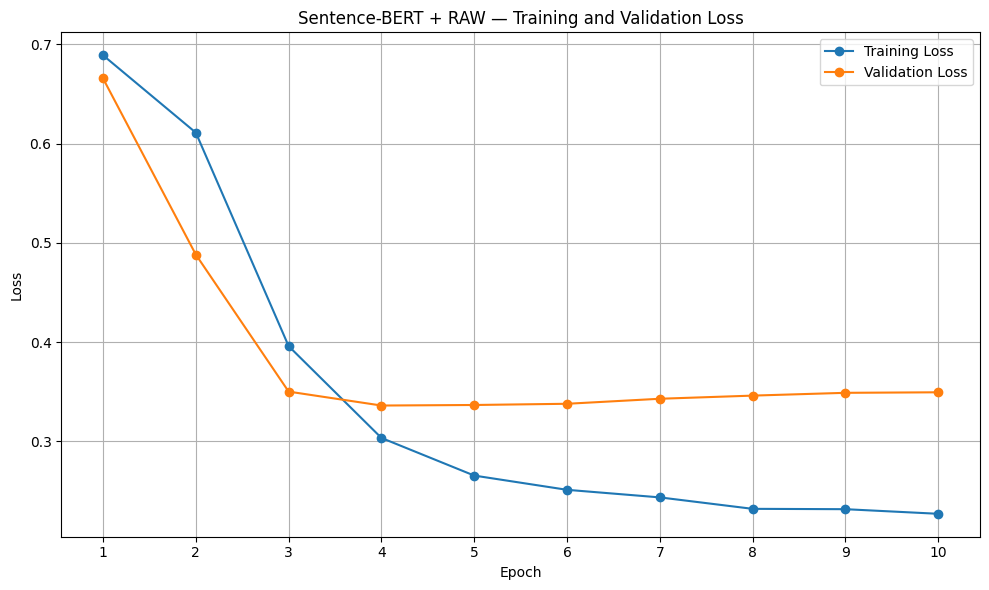

✓ Loss graph shown and saved


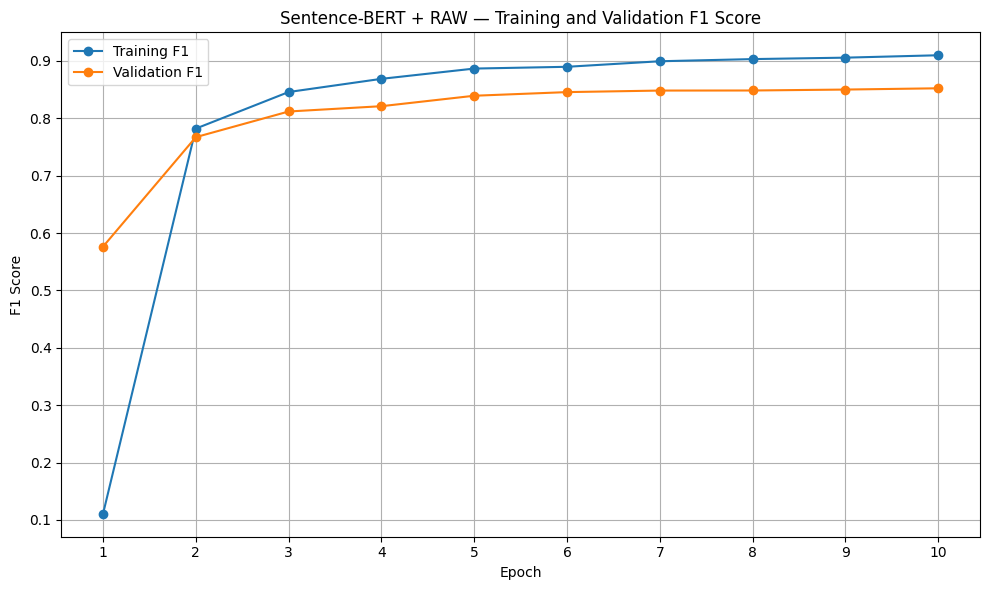

✓ F1 graph shown and saved


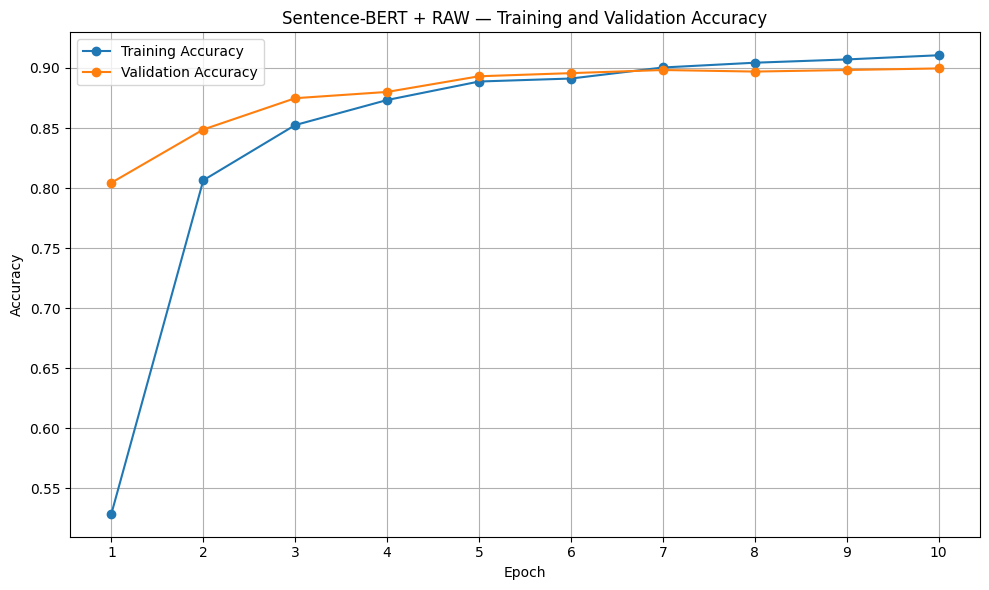

✓ Accuracy graph shown and saved


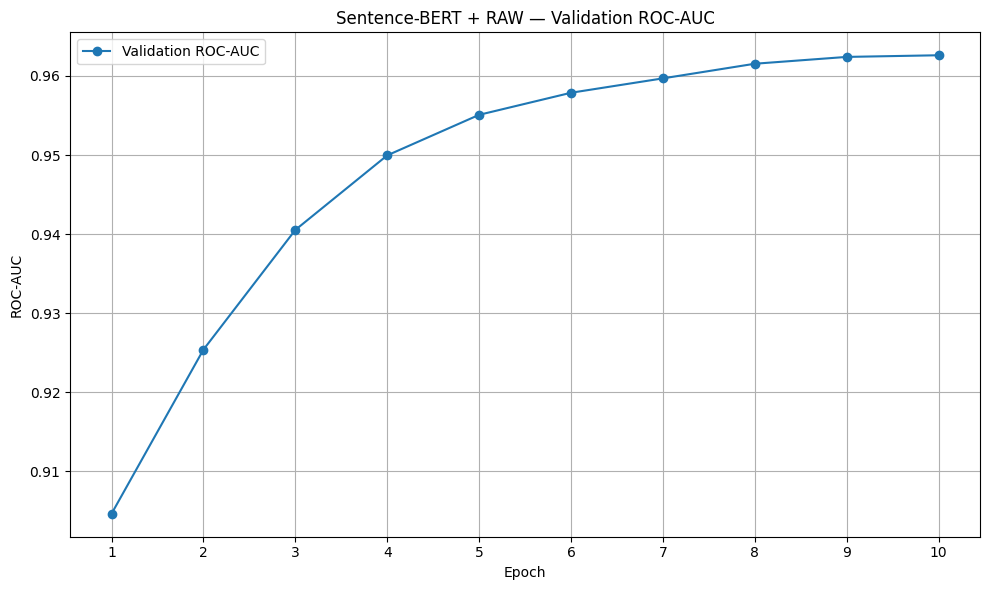

✓ ROC-AUC graph shown and saved


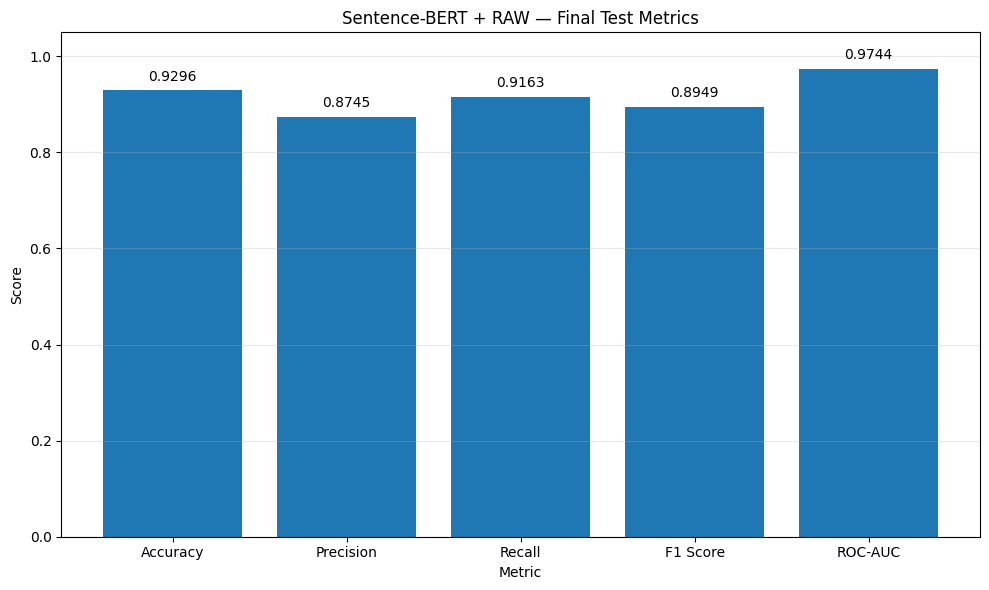

✓ Final metrics graph shown and saved


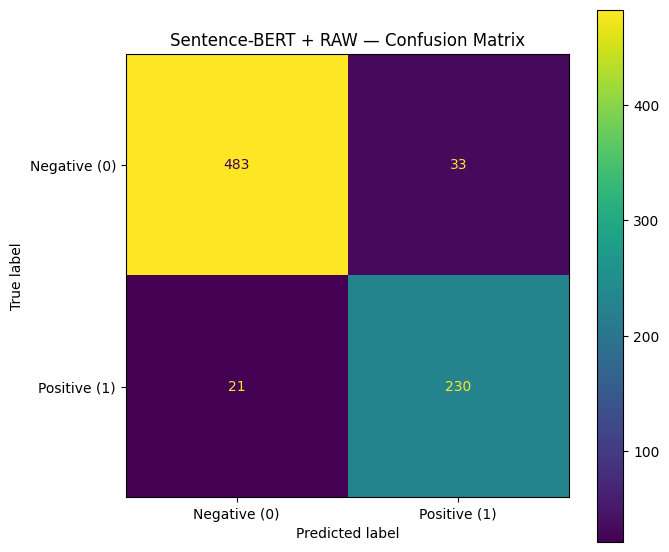

✓ Confusion matrix shown and saved
SENTENCE-BERT + RAW — COMPLETE RESULTS TABLE

COMPLETE FINAL RESULTS TABLE



,Category,Metric,Value
0,Experiment,Model,sentence-transformers/all-mpnet-base-v2
1,Experiment,Cleaning Method,RAW
2,Experiment,Context Length,512
3,Experiment,Transformer Frozen,True
4,Best Model,Best Epoch,10
5,Best Model,Best Validation F1,0.852207
6,Test Dataset,Test Users,767
7,Test Metrics,Test Loss,0.207232
8,Test Metrics,Test Accuracy,0.929596
9,Test Metrics,Test Precision,0.874525



✓ Complete results table saved:
/kaggle/working/sentencebert_raw/results/sentencebert_raw_complete_results.csv

SUMMARY TABLE


,Metric,Value
0,Best Epoch,10.000000
1,Best Validation F1,0.852207
2,Best Validation Accuracy,0.899609
3,Best Validation ROC-AUC,0.962606
4,Final Test Accuracy,0.929596
5,Final Test Precision,0.874525
6,Final Test Recall,0.916335
7,Final Test F1,0.894942
8,Final Test ROC-AUC,0.974420



✓ Summary table saved:
/kaggle/working/sentencebert_raw/results/sentencebert_raw_summary_table.csv

SENTENCE-BERT + RAW — RESULTS COMPLETE

Best Epoch: 10
Best Validation F1: 0.8522

FINAL TEST RESULTS
Test Loss:      0.2072
Test Accuracy:  0.9296
Test Precision: 0.8745
Test Recall:    0.9163
Test F1 Score:  0.8949
Test ROC-AUC:   0.9744

CONFUSION MATRIX
TN: 483
FP: 33
FN: 21
TP: 230

✓ Results table created
✓ Results table saved
✓ Summary table created
✓ Summary table saved

CELL 14 — FINAL SECTION COMPLETE


In [15]:
# ============================================================
# CELL 14 — SENTENCE-BERT + RAW
# SAVE HISTORY + ALL GRAPHS + COMPLETE RESULTS TABLE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay


print("=" * 60)
print("SENTENCE-BERT + RAW — GRAPHS AND RESULTS TABLE")
print("=" * 60)


# ============================================================
# CREATE GRAPH DIRECTORY
# ============================================================

GRAPH_DIR = os.path.join(
    RESULT_DIR,
    "graphs"
)

os.makedirs(
    GRAPH_DIR,
    exist_ok=True
)

print(f"\n✓ Graph directory: {GRAPH_DIR}")


# ============================================================
# CONVERT EXISTING HISTORY TO DATAFRAME
# ============================================================

assert "history" in globals(), (
    "Training history variable 'history' is not available."
)

history_df = pd.DataFrame(history)

print("\n✓ Training history recovered from memory")
print(f"✓ Epochs available: {len(history_df)}")


# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

history_csv_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_training_history.csv"
)

history_df.to_csv(
    history_csv_path,
    index=False
)


# JSON-safe version
history_json_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_training_history.json"
)

history_json_safe = (
    history_df
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .where(pd.notnull(history_df), None)
    .to_dict(orient="records")
)

with open(
    history_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        history_json_safe,
        f,
        indent=2
    )


print("✓ Training history CSV saved")
print("✓ Training history JSON saved")


# ============================================================
# TRAINING HISTORY TABLE
# ============================================================

print("\n" + "=" * 60)
print("TRAINING HISTORY")
print("=" * 60)

display(history_df)


# ============================================================
# GRAPH 1 — TRAINING + VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title(
    "Sentence-BERT + RAW — Training and Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True)

plt.tight_layout()


loss_graph_path = os.path.join(
    GRAPH_DIR,
    "sentencebert_raw_loss_curve.png"
)

plt.savefig(
    loss_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("✓ Loss graph shown and saved")


# ============================================================
# GRAPH 2 — TRAINING + VALIDATION F1
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_f1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.title(
    "Sentence-BERT + RAW — Training and Validation F1 Score"
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True)

plt.tight_layout()


f1_graph_path = os.path.join(
    GRAPH_DIR,
    "sentencebert_raw_f1_curve.png"
)

plt.savefig(
    f1_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("✓ F1 graph shown and saved")


# ============================================================
# GRAPH 3 — TRAINING + VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title(
    "Sentence-BERT + RAW — Training and Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True)

plt.tight_layout()


accuracy_graph_path = os.path.join(
    GRAPH_DIR,
    "sentencebert_raw_accuracy_curve.png"
)

plt.savefig(
    accuracy_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("✓ Accuracy graph shown and saved")


# ============================================================
# GRAPH 4 — VALIDATION ROC-AUC
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"],
    marker="o",
    label="Validation ROC-AUC"
)

plt.title(
    "Sentence-BERT + RAW — Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")

plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True)

plt.tight_layout()


roc_auc_graph_path = os.path.join(
    GRAPH_DIR,
    "sentencebert_raw_validation_roc_auc.png"
)

plt.savefig(
    roc_auc_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("✓ ROC-AUC graph shown and saved")


# ============================================================
# FINAL TEST METRICS
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

metric_values = [
    test_accuracy,
    test_precision,
    test_recall,
    test_f1,
    test_roc_auc
]


# ============================================================
# GRAPH 5 — FINAL TEST METRICS
# ============================================================

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metric_names,
    metric_values
)

plt.title(
    "Sentence-BERT + RAW — Final Test Metrics"
)

plt.xlabel("Metric")
plt.ylabel("Score")

plt.ylim(0, 1.05)

plt.grid(
    axis="y",
    alpha=0.3
)


for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )


plt.tight_layout()


metrics_graph_path = os.path.join(
    GRAPH_DIR,
    "sentencebert_raw_final_metrics.png"
)

plt.savefig(
    metrics_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("✓ Final metrics graph shown and saved")


# ============================================================
# GRAPH 6 — CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Negative (0)",
        "Positive (1)"
    ]
)

cm_display.plot(
    values_format="d",
    ax=ax
)

ax.set_title(
    "Sentence-BERT + RAW — Confusion Matrix"
)

plt.tight_layout()


confusion_matrix_path = os.path.join(
    GRAPH_DIR,
    "sentencebert_raw_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("✓ Confusion matrix shown and saved")


# ============================================================
# FIX — COMPLETE FINAL RESULTS TABLE
# ============================================================

print("=" * 60)
print("SENTENCE-BERT + RAW — COMPLETE RESULTS TABLE")
print("=" * 60)


# Create rows explicitly so every column has exactly
# the same number of values

results_rows = [
    
    # Experiment configuration
    {
        "Category": "Experiment",
        "Metric": "Model",
        "Value": "sentence-transformers/all-mpnet-base-v2"
    },
    {
        "Category": "Experiment",
        "Metric": "Cleaning Method",
        "Value": "RAW"
    },
    {
        "Category": "Experiment",
        "Metric": "Context Length",
        "Value": 512
    },
    {
        "Category": "Experiment",
        "Metric": "Transformer Frozen",
        "Value": True
    },

    # Best model
    {
        "Category": "Best Model",
        "Metric": "Best Epoch",
        "Value": checkpoint["epoch"]
    },
    {
        "Category": "Best Model",
        "Metric": "Best Validation F1",
        "Value": checkpoint["best_val_f1"]
    },

    # Test dataset
    {
        "Category": "Test Dataset",
        "Metric": "Test Users",
        "Value": len(all_labels)
    },

    # Test metrics
    {
        "Category": "Test Metrics",
        "Metric": "Test Loss",
        "Value": test_loss
    },
    {
        "Category": "Test Metrics",
        "Metric": "Test Accuracy",
        "Value": test_accuracy
    },
    {
        "Category": "Test Metrics",
        "Metric": "Test Precision",
        "Value": test_precision
    },
    {
        "Category": "Test Metrics",
        "Metric": "Test Recall",
        "Value": test_recall
    },
    {
        "Category": "Test Metrics",
        "Metric": "Test F1 Score",
        "Value": test_f1
    },
    {
        "Category": "Test Metrics",
        "Metric": "Test ROC-AUC",
        "Value": test_roc_auc
    },

    # Confusion matrix
    {
        "Category": "Confusion Matrix",
        "Metric": "True Negatives",
        "Value": tn
    },
    {
        "Category": "Confusion Matrix",
        "Metric": "False Positives",
        "Value": fp
    },
    {
        "Category": "Confusion Matrix",
        "Metric": "False Negatives",
        "Value": fn
    },
    {
        "Category": "Confusion Matrix",
        "Metric": "True Positives",
        "Value": tp
    }
]


# ============================================================
# CREATE RESULTS TABLE
# ============================================================

results_table = pd.DataFrame(results_rows)

print("\nCOMPLETE FINAL RESULTS TABLE\n")

display(results_table)


# ============================================================
# SAVE COMPLETE RESULTS TABLE
# ============================================================

results_csv_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_complete_results.csv"
)

results_table.to_csv(
    results_csv_path,
    index=False
)

print(f"\n✓ Complete results table saved:")
print(results_csv_path)


# ============================================================
# SUMMARY TABLE
# ============================================================

# Best epoch based on highest validation F1
best_epoch_row = history_df.loc[
    history_df["val_f1"].idxmax()
]


summary_rows = [
    
    {
        "Metric": "Best Epoch",
        "Value": int(best_epoch_row["epoch"])
    },
    {
        "Metric": "Best Validation F1",
        "Value": float(best_epoch_row["val_f1"])
    },
    {
        "Metric": "Best Validation Accuracy",
        "Value": float(best_epoch_row["val_accuracy"])
    },
    {
        "Metric": "Best Validation ROC-AUC",
        "Value": float(best_epoch_row["val_roc_auc"])
    },
    {
        "Metric": "Final Test Accuracy",
        "Value": float(test_accuracy)
    },
    {
        "Metric": "Final Test Precision",
        "Value": float(test_precision)
    },
    {
        "Metric": "Final Test Recall",
        "Value": float(test_recall)
    },
    {
        "Metric": "Final Test F1",
        "Value": float(test_f1)
    },
    {
        "Metric": "Final Test ROC-AUC",
        "Value": float(test_roc_auc)
    }
]


summary_table = pd.DataFrame(summary_rows)


print("\n" + "=" * 60)
print("SUMMARY TABLE")
print("=" * 60)

display(summary_table)


# ============================================================
# SAVE SUMMARY TABLE
# ============================================================

summary_csv_path = os.path.join(
    RESULT_DIR,
    "sentencebert_raw_summary_table.csv"
)

summary_table.to_csv(
    summary_csv_path,
    index=False
)

print(f"\n✓ Summary table saved:")
print(summary_csv_path)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("SENTENCE-BERT + RAW — RESULTS COMPLETE")
print("=" * 60)

print(f"\nBest Epoch: {int(best_epoch_row['epoch'])}")
print(f"Best Validation F1: {best_epoch_row['val_f1']:.4f}")

print("\nFINAL TEST RESULTS")
print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1 Score:  {test_f1:.4f}")
print(f"Test ROC-AUC:   {test_roc_auc:.4f}")

print("\nCONFUSION MATRIX")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\n✓ Results table created")
print("✓ Results table saved")
print("✓ Summary table created")
print("✓ Summary table saved")

print("\n" + "=" * 60)
print("CELL 14 — FINAL SECTION COMPLETE")
print("=" * 60)

t-SNE REPRESENTATION ANALYSIS
SENTENCE-BERT + SELECTIVE

Extracting fused model representations...
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION
Representation shape: (767, 832)
Number of test users: 767
Representation dimensions: 832
Negative users: 516
Positive users: 251

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 79.67%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


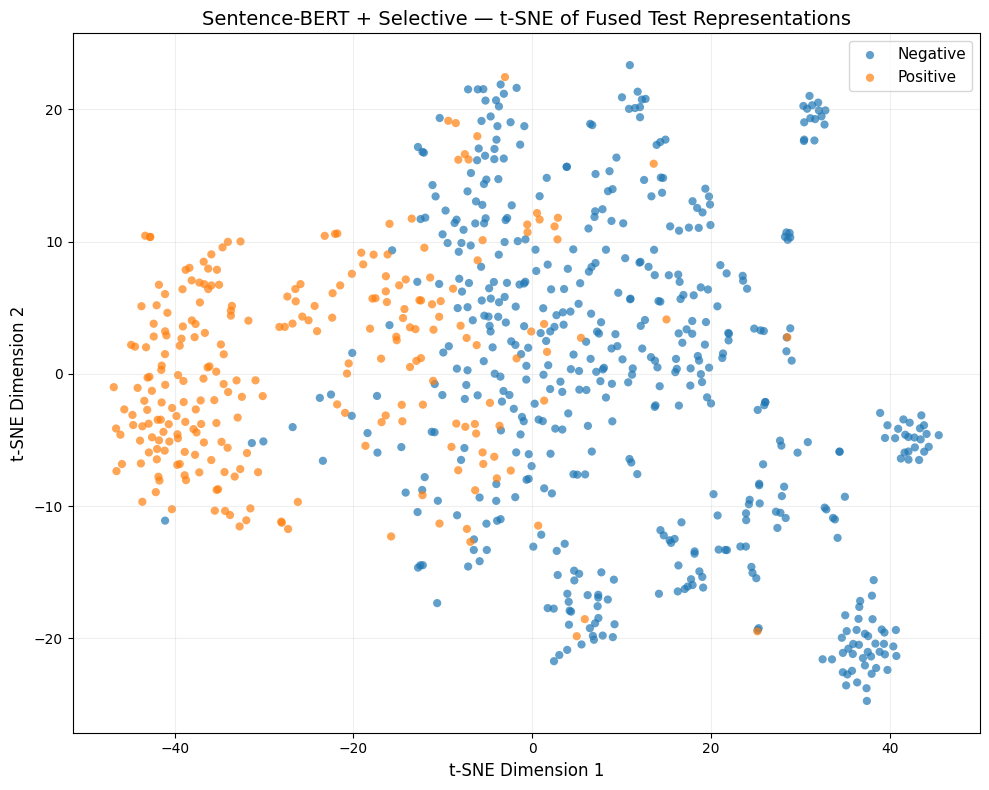


t-SNE ANALYSIS COMPLETE
✓ Sentence-BERT fused representation extracted
✓ Text representation = 768
✓ Metadata representation = 64
✓ Fusion = 832 dimensions
✓ No metadata gate used
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ Coordinates saved:
/kaggle/working/sentencebert_raw/explainability/tsne/sentencebert_selective_tsne_coordinates.csv
✓ Graph saved:
/kaggle/working/sentencebert_raw/explainability/tsne/sentencebert_selective_tsne.png
✓ Graph displayed above
✓ Configuration saved


In [19]:
# ============================================================
# EXPLAINABILITY — CELL 1
# SENTENCE-BERT + SELECTIVE
# t-SNE: FUSED REPRESENTATION → PCA → t-SNE
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("SENTENCE-BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()


# ============================================================
# EXTRACT EXACT FUSED REPRESENTATIONS
# ============================================================

fused_representations = []
test_labels = []

print()
print("Extracting fused model representations...")

with torch.no_grad():

    # IMPORTANT:
    # Sentence-BERT notebook defines:
    # test_sentencebert_raw_loader
    #
    # It does NOT define:
    # test_sentencebert_selective_loader

    for batch_idx, batch in enumerate(
        test_sentencebert_raw_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)


        # ----------------------------------------------------
        # EXACT SENTENCE-BERT MODEL OUTPUT
        # ----------------------------------------------------

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        # ----------------------------------------------------
        # EXACT TEXT REPRESENTATION
        # ----------------------------------------------------

        text_representation = output[
            "text_representation"
        ]


        # ----------------------------------------------------
        # EXACT METADATA REPRESENTATION
        # ----------------------------------------------------

        metadata_representation = output[
            "metadata_representation"
        ]


        # ----------------------------------------------------
        # EXACT SENTENCE-BERT FUSION
        #
        # IMPORTANT:
        # Sentence-BERT notebook has NO metadata gate.
        # Fusion = 768 + 64 = 832
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                metadata_representation
            ],
            dim=1
        )


        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )


        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or
            batch_idx ==
            len(
                test_sentencebert_raw_loader
            )
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/"
                f"{len(test_sentencebert_raw_loader)}"
            )


# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)


# ============================================================
# INTEGRITY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION")
print("=" * 70)

print(
    "Representation shape:",
    fused_representations.shape
)

print(
    "Number of test users:",
    len(test_labels)
)

print(
    "Representation dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert (
    fused_representations.shape[1]
    ==
    832
)

assert np.isfinite(
    fused_representations
).all()


# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

explained_variance = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{explained_variance * 100:.2f}%"
)


# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)


# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})


tsne_csv_path = os.path.join(
    TSNE_DIR,
    "sentencebert_selective_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)


# ============================================================
# PUBLICATION-QUALITY PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)


plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Negative",
    edgecolors="none"
)


plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=35,
    alpha=0.70,
    label="Positive",
    edgecolors="none"
)


plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "Sentence-BERT + Selective — "
    "t-SNE of Fused Test Representations",
    fontsize=14
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()


tsne_plot_path = os.path.join(
    TSNE_DIR,
    "sentencebert_selective_tsne.png"
)


# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)


# DISPLAY
plt.show()

plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "Sentence-BERT",

    "model_name":
        MODEL_NAME,

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "test_users":
        int(
            len(test_labels)
        ),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "fusion":
        "768 + 64 = 832",

    "metadata_gate":
        False,

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            explained_variance
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED
}


with open(
    os.path.join(
        TSNE_DIR,
        "sentencebert_selective_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )


# ============================================================
# FINAL OUTPUT
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Sentence-BERT fused representation extracted"
)

print(
    "✓ Text representation = 768"
)

print(
    "✓ Metadata representation = 64"
)

print(
    "✓ Fusion = 832 dimensions"
)

print(
    "✓ No metadata gate used"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ Graph displayed above"
)

print(
    "✓ Configuration saved"
)

GRAD-CAM EXPLAINABILITY
SENTENCE-BERT + SELECTIVE
TEST PREDICTIONS READY
Test samples : 767
SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.7927
TN : test index 0 | true=0 | pred=0 | probability=0.1341
FP : test index 25 | true=0 | pred=1 | probability=0.5621
FN : test index 56 | true=1 | pred=0 | probability=0.4798
PROCESSING TP
Test index : 1


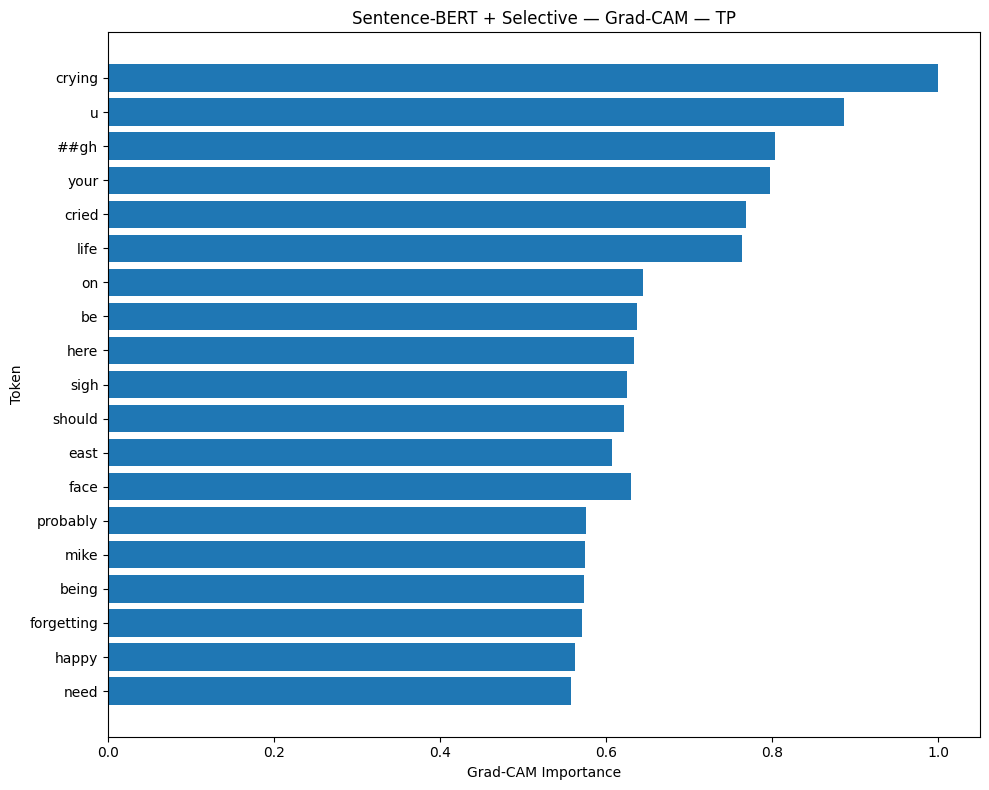

Saved: /kaggle/working/sentencebert_raw/explainability/gradcam/sentencebert_selective_gradcam_tp_tokens.csv
PROCESSING TN
Test index : 0


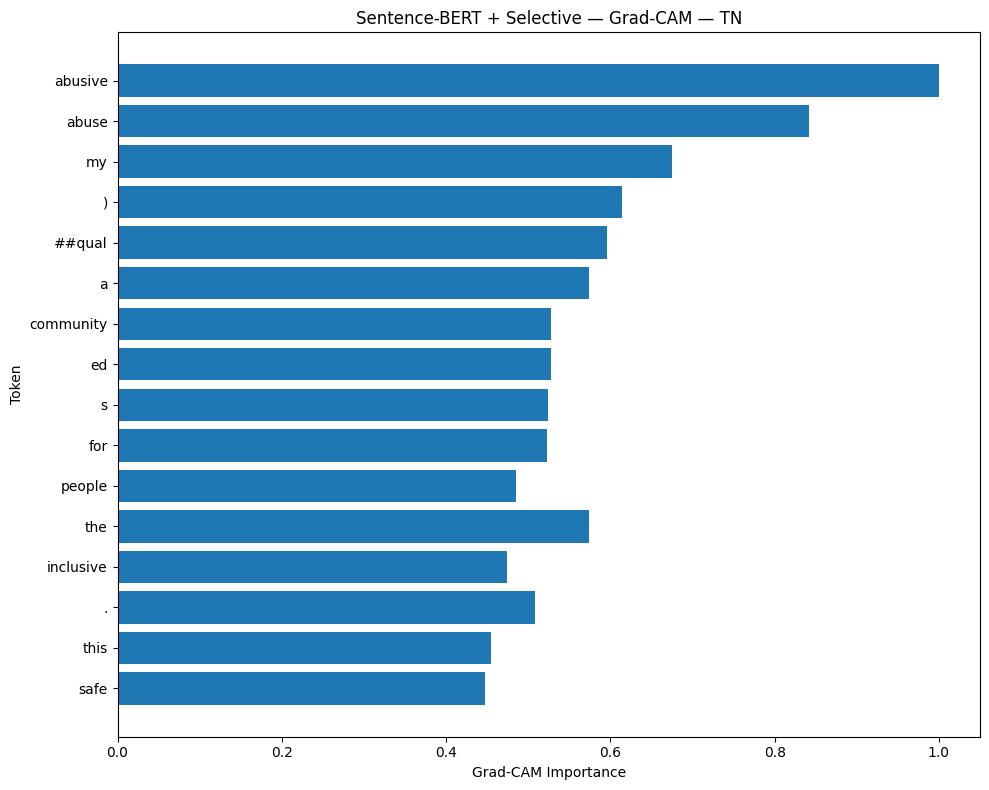

Saved: /kaggle/working/sentencebert_raw/explainability/gradcam/sentencebert_selective_gradcam_tn_tokens.csv
PROCESSING FP
Test index : 25


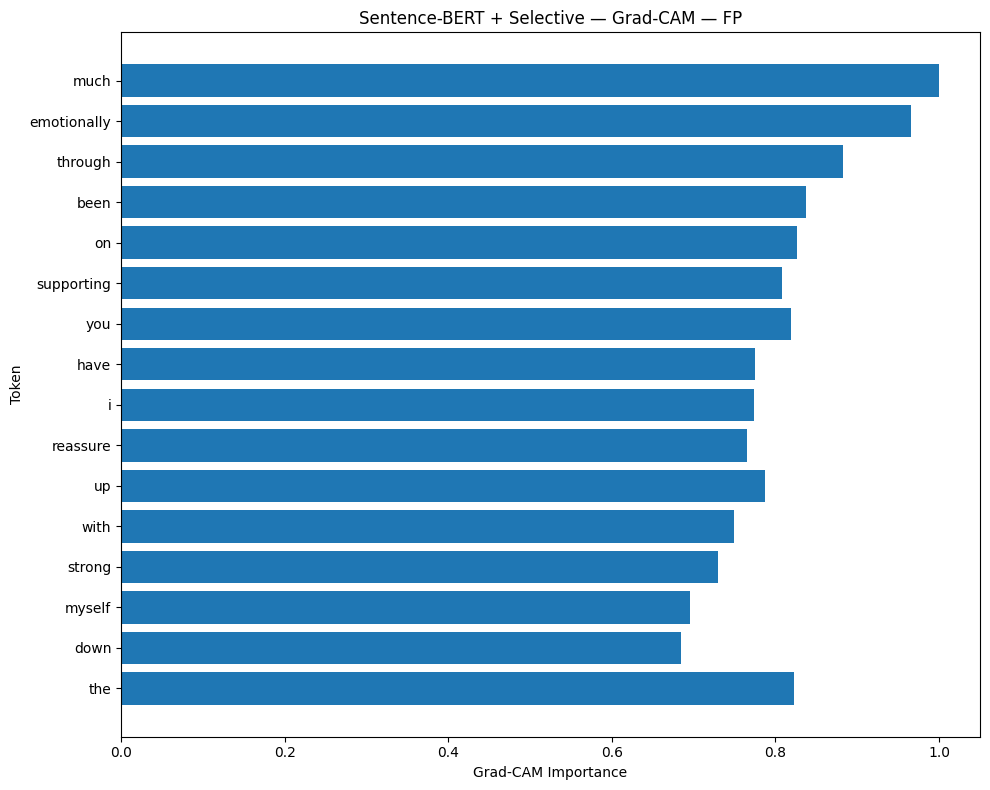

Saved: /kaggle/working/sentencebert_raw/explainability/gradcam/sentencebert_selective_gradcam_fp_tokens.csv
PROCESSING FN
Test index : 56


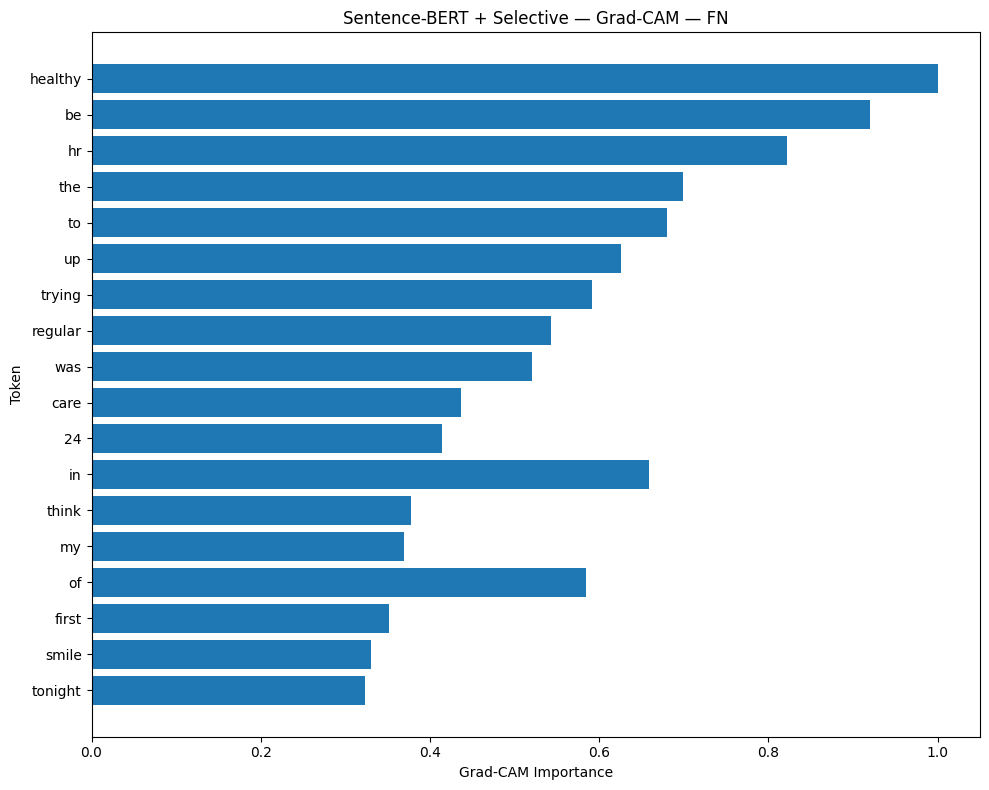

Saved: /kaggle/working/sentencebert_raw/explainability/gradcam/sentencebert_selective_gradcam_fn_tokens.csv
GRAD-CAM COMPLETE
Output directory:
/kaggle/working/sentencebert_raw/explainability/gradcam
Configuration saved:
/kaggle/working/sentencebert_raw/explainability/gradcam/sentencebert_selective_gradcam_config.json
Cases processed: ['TP', 'TN', 'FP', 'FN']


In [21]:
# ============================================================
# EXPLAINABILITY — CELL 2
# SENTENCE-BERT + SELECTIVE
# GRAD-CAM: TOKEN-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


print("=" * 70)
print("GRAD-CAM EXPLAINABILITY")
print("SENTENCE-BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED GRAD-CAM SETTINGS
# ============================================================

GRADCAM_SEED = 42
GRADCAM_TOP_TOKENS = 20

np.random.seed(GRADCAM_SEED)
torch.manual_seed(GRADCAM_SEED)


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()


# ============================================================
# STEP 1 — CALCULATE TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_sentencebert_raw_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            batch[
                "labels"
            ]
            .cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )


labels_np = np.array(
    labels_np
)

preds_np = np.array(
    preds_np
)

probs_np = np.array(
    probs_np
)


print("=" * 70)
print("TEST PREDICTIONS READY")
print(f"Test samples : {len(labels_np)}")
print("=" * 70)


# ============================================================
# STEP 2 — SELECT TP / TN / FP / FN CASES
# ============================================================

selected_cases = {}


tp_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 1)
)[0]


tn_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 0)
)[0]


fp_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 1)
)[0]


fn_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 0)
)[0]


if len(tp_candidates) > 0:

    selected_cases[
        "TP"
    ] = int(
        tp_candidates[0]
    )


if len(tn_candidates) > 0:

    selected_cases[
        "TN"
    ] = int(
        tn_candidates[0]
    )


if len(fp_candidates) > 0:

    selected_cases[
        "FP"
    ] = int(
        fp_candidates[0]
    )


if len(fn_candidates) > 0:

    selected_cases[
        "FN"
    ] = int(
        fn_candidates[0]
    )


print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_type, test_index in selected_cases.items():

    print(
        f"{case_type} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )


# ============================================================
# STEP 3 — GRAD-CAM COMPUTATION
# ============================================================

def compute_sentencebert_selective_gradcam(
    test_index
):

    sample = test_sentencebert_raw_dataset[
        test_index
    ]


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # SENTENCE-BERT ENCODER
    # --------------------------------------------------------
    # IMPORTANT:
    # The actual Sentence-BERT notebook stores the
    # transformer as model.encoder
    # --------------------------------------------------------

    model.zero_grad(
        set_to_none=True
    )


    with torch.no_grad():

        sentencebert_output = model.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )


    hidden_states = (
        sentencebert_output
        .last_hidden_state
        .detach()
    )


    hidden_states.requires_grad_(
        True
    )

    hidden_states.retain_grad()


    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    attention_features = (
        model.attention_projection(
            hidden_states
        )
    )


    attention_scores = (
        model.attention_score(
            torch.tanh(
                attention_features
            )
        )
        .squeeze(-1)
    )


    attention_scores = (
        attention_scores.float()
    )


    attention_scores = (
        attention_scores.masked_fill(
            attention_mask == 0,
            torch.finfo(
                attention_scores.dtype
            ).min
        )
    )


    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )


    text_representation = (
        torch.sum(
            hidden_states *
            attention_weights.unsqueeze(-1),
            dim=1
        )
    )


    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = (
        model.metadata_branch(
            metadata
        )
    )


    # --------------------------------------------------------
    # FUSION + CLASSIFIER
    # --------------------------------------------------------
    # Sentence-BERT notebook:
    # text representation = 768
    # metadata representation = 64
    # fused representation = 832
    #
    # NO metadata gate
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            metadata_representation
        ],
        dim=1
    )


    logits = model.classifier(
        fused
    )


    positive_logit = logits[
        :, 1
    ]


    # --------------------------------------------------------
    # BACKWARD
    # --------------------------------------------------------

    positive_logit.backward()


    gradients = (
        hidden_states.grad
    )


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    channel_weights = (
        gradients.mean(
            dim=1,
            keepdim=True
        )
    )


    gradcam = (
        channel_weights *
        hidden_states
    ).sum(
        dim=-1
    )


    gradcam = torch.relu(
        gradcam
    )


    gradcam = (
        gradcam
        .squeeze(0)
    )


    attention_weights = (
        attention_weights
        .squeeze(0)
    )


    valid_mask = (
        attention_mask
        .squeeze(0)
    )


    gradcam = (
        gradcam
        .detach()
        .cpu()
        .numpy()
    )


    attention_weights = (
        attention_weights
        .detach()
        .cpu()
        .numpy()
    )


    valid_mask = (
        valid_mask
        .detach()
        .cpu()
        .numpy()
    )


    gradcam = (
        gradcam *
        valid_mask
    )


    if gradcam.max() > 0:

        gradcam = (
            gradcam /
            gradcam.max()
        )


    return {

        "gradcam":
            gradcam,

        "attention_weights":
            attention_weights,

        "input_ids":
            sample[
                "input_ids"
            ]
            .cpu()
            .numpy(),

        "attention_mask":
            sample[
                "attention_mask"
            ]
            .cpu()
            .numpy(),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            )
    }


# ============================================================
# STEP 4 — TOKEN INFORMATION
# ============================================================

def get_token_information(
    input_ids,
    attention_mask,
    gradcam,
    tokenizer,
    top_tokens=20
):

    token_ids = input_ids[
        attention_mask.astype(bool)
    ]


    importance = gradcam[
        attention_mask.astype(bool)
    ]


    tokens = tokenizer.convert_ids_to_tokens(
        token_ids.tolist()
    )


    token_information = []


    for token, score in zip(
        tokens,
        importance
    ):

        if token in tokenizer.all_special_tokens:

            continue


        token_information.append(
            {
                "token":
                    token,

                "importance":
                    float(score)
            }
        )


    token_information = sorted(
        token_information,
        key=lambda x:
            x["importance"],
        reverse=True
    )


    for rank, item in enumerate(
        token_information,
        start=1
    ):

        item[
            "rank"
        ] = rank


    return token_information[
        :top_tokens
    ]


# ============================================================
# STEP 5 — RUN TP / TN / FP / FN
# ============================================================

all_gradcam_results = []


for case_type, test_index in selected_cases.items():

    print("=" * 70)
    print(f"PROCESSING {case_type}")
    print(f"Test index : {test_index}")
    print("=" * 70)


    result = (
        compute_sentencebert_selective_gradcam(
            test_index
        )
    )


    token_information = (
        get_token_information(
            result[
                "input_ids"
            ],

            result[
                "attention_mask"
            ],

            result[
                "gradcam"
            ],

            sentencebert_raw_tokenizer,

            GRADCAM_TOP_TOKENS
        )
    )


    token_df = pd.DataFrame(
        token_information
    )


    # --------------------------------------------------------
    # SAVE TOKEN CSV
    # --------------------------------------------------------

    token_csv_path = os.path.join(
        GRADCAM_DIR,
        (
            "sentencebert_selective_gradcam_"
            f"{case_type.lower()}_tokens.csv"
        )
    )


    token_df.to_csv(
        token_csv_path,
        index=False
    )


    # --------------------------------------------------------
    # TOP TOKEN PLOT
    # --------------------------------------------------------

    plot_df = token_df.sort_values(
        "importance",
        ascending=True
    )


    plt.figure(
        figsize=(10, 8)
    )


    plt.barh(
        plot_df[
            "token"
        ],
        plot_df[
            "importance"
        ]
    )


    plt.xlabel(
        "Grad-CAM Importance"
    )


    plt.ylabel(
        "Token"
    )


    plt.title(
        (
            "Sentence-BERT + Selective — "
            f"Grad-CAM — {case_type}"
        )
    )


    plt.tight_layout()


    plot_path = os.path.join(
        GRADCAM_DIR,
        (
            "sentencebert_selective_gradcam_"
            f"{case_type.lower()}.png"
        )
    )


    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()
    plt.close()


    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    all_gradcam_results.append(
        {

            "case_type":
                case_type,

            "test_index":
                test_index,

            "true_label":
                result[
                    "true_label"
                ],

            "predicted_label":
                result[
                    "predicted_label"
                ],

            "positive_probability":
                result[
                    "positive_probability"
                ],

            "top_tokens":
                token_information
        }
    )


    print(
        f"Saved: {token_csv_path}"
    )


# ============================================================
# STEP 6 — SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        MODEL_NAME,

    "architecture":
        "Sentence-BERT + Metadata Branch",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "method":
        "Transformer Grad-CAM",

    "target":
        "Positive class logit",

    "hidden_dimension":
        int(
            model.encoder.config.hidden_size
        ),

    "text_representation_dimension":
        768,

    "metadata_representation_dimension":
        64,

    "fused_representation_dimension":
        832,

    "metadata_gate":
        False,

    "cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "top_tokens_displayed":
        GRADCAM_TOP_TOKENS,

    "random_seed":
        GRADCAM_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"
}


config_path = os.path.join(
    GRADCAM_DIR,
    "sentencebert_selective_gradcam_config.json"
)


with open(
    config_path,
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=4
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("=" * 70)
print("GRAD-CAM COMPLETE")
print("=" * 70)

print(
    f"Output directory:\n{GRADCAM_DIR}"
)

print(
    f"Configuration saved:\n{config_path}"
)

print(
    "Cases processed:",
    list(
        selected_cases.keys()
    )
)

print("=" * 70)

In [24]:
print("hello")

hello


SHAP ANALYSIS
SENTENCE-BERT + SELECTIVE
✓ Metadata features confirmed: 53
✓ Sentence-BERT + Selective model loaded
✓ Evaluation mode enabled

SHAP BACKGROUND
Background samples: 50
Metadata dimensions: 53

SHAP TEST USERS
Negative users: 50
Positive users: 50
Total users: 100

GENERATING SHAP EXPLANATIONS
Processed 1/100
Processed 10/100
Processed 20/100
Processed 30/100
Processed 40/100
Processed 50/100
Processed 60/100
Processed 70/100
Processed 80/100
Processed 90/100
Processed 100/100

TOP SHAP FEATURES
 rank                  feature  mean_abs_shap_value
    1              lda_topic_2             0.165408
    2           negation_ratio             0.105280
    3              lda_topic_9             0.063360
    4               engagement             0.056891
    5             lda_topic_17             0.050096
    6        posting_frequency             0.049221
    7            friends_count             0.046236
    8         punctuation_freq             0.043940
    9             l

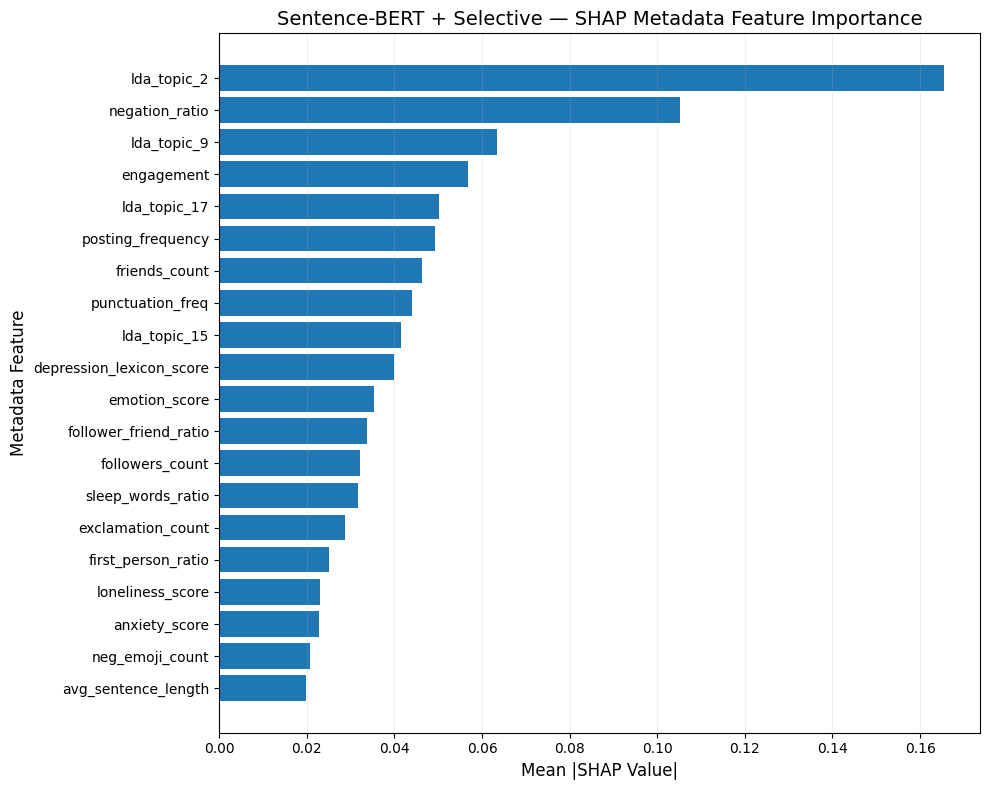

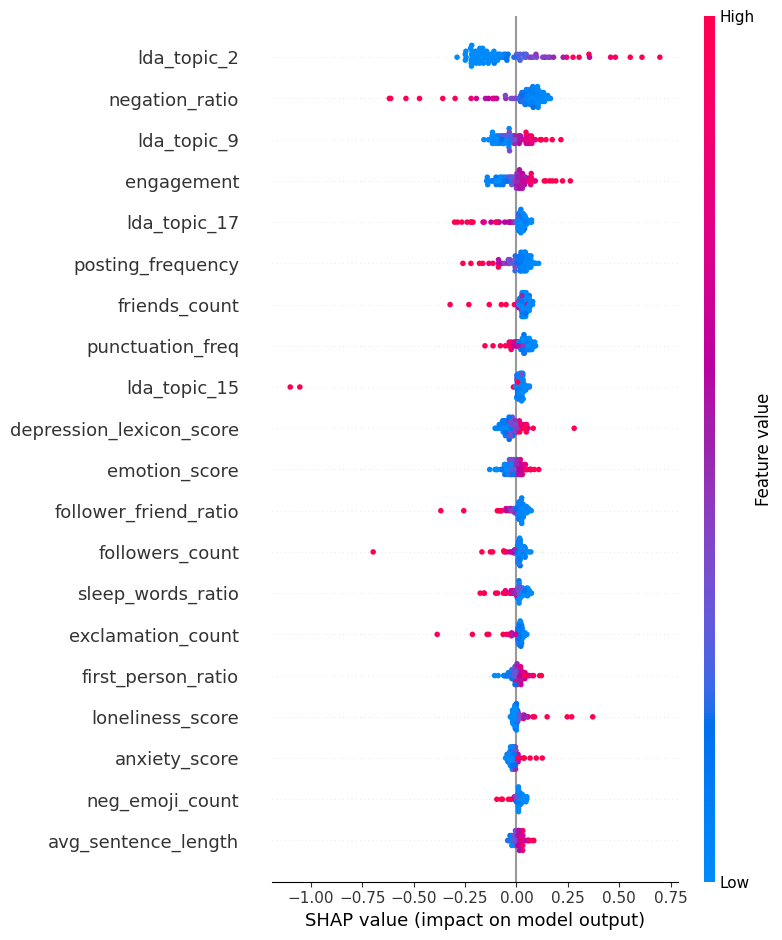


SHAP ANALYSIS COMPLETE
✓ 53 metadata features used
✓ 50 negative + 50 positive test users targeted
✓ Metadata-only SHAP explanations generated
✓ Global feature importance calculated
✓ SHAP summary plot saved
✓ Top feature plot saved
✓ SHAP CSV saved
✓ Configuration saved

SHAP output directory: /kaggle/working/sentencebert_raw/explainability/shap


In [25]:
# ============================================================
# EXPLAINABILITY — CELL 3
# SENTENCE-BERT + SELECTIVE
# SHAP: METADATA-LEVEL GLOBAL EXPLANATION
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap


print("=" * 70)
print("SHAP ANALYSIS")
print("SENTENCE-BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


# ============================================================
# EXACT 53 METADATA FEATURE NAMES
# ============================================================

behavioral_features = [

    "posting_frequency",

    "follower_friend_ratio",

    "night_posting_ratio",

    "engagement",

    "followers_count",

    "friends_count",

    "statuses_count",

    "favourites_count"
]


linguistic_features = [

    "first_person_ratio",

    "negation_ratio",

    "uppercase_ratio",

    "punctuation_freq"
]


readability_features = [

    "flesch_reading_ease",

    "gunning_fog",

    "flesch_kincaid_grade"
]


emotional_features = [

    "sentiment_score",

    "emotion_score",

    "pos_emoji_count",

    "neg_emoji_count",

    "emoji_density",

    "exclamation_count"
]


psychological_features = [

    "depression_lexicon_score",

    "hopelessness_score",

    "loneliness_score",

    "anxiety_score",

    "sleep_words_ratio",

    "fatigue_words_ratio",

    "selfharm_keywords_ratio"
]


writing_style_features = [

    "avg_sentence_length",

    "lexical_diversity",

    "word_count",

    "avg_paragraph_length",

    "repeated_letters"
]


lda_features = [
    f"lda_topic_{i}"
    for i in range(1, 21)
]


raw_metadata_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
    + lda_features
)


assert len(
    raw_metadata_features
) == 53


print(
    f"✓ Metadata features confirmed: "
    f"{len(raw_metadata_features)}"
)


# ============================================================
# MODEL
# ============================================================

model.eval()

print("✓ Sentence-BERT + Selective model loaded")
print("✓ Evaluation mode enabled")


# ============================================================
# SHAP WRAPPER
# FIX TEXT INPUT FOR EACH USER
# VARY ONLY METADATA
# ============================================================

class MetadataSHAPWrapper(nn.Module):

    def __init__(
        self,
        model,
        input_ids,
        attention_mask
    ):

        super().__init__()

        self.model = model

        self.register_buffer(
            "input_ids",
            input_ids
        )

        self.register_buffer(
            "attention_mask",
            attention_mask
        )


    def forward(
        self,
        metadata
    ):

        batch_size = metadata.shape[0]


        input_ids = self.input_ids.expand(
            batch_size,
            -1
        )


        attention_mask = (
            self.attention_mask.expand(
                batch_size,
                -1
            )
        )


        output = self.model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )


        # Positive / depression class logit
        return output[
            "logits"
        ][:, 1:2]


# ============================================================
# BACKGROUND METADATA
# ============================================================

background_metadata = (

    train_sentencebert_raw_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]

    .clone()
    .detach()
    .float()
    .to(device)
)


print()
print("=" * 70)
print("SHAP BACKGROUND")
print("=" * 70)

print(
    "Background samples:",
    background_metadata.shape[0]
)

print(
    "Metadata dimensions:",
    background_metadata.shape[1]
)


# ============================================================
# TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels = np.asarray(
    test_sentencebert_raw_dataset.labels
)


negative_indices = np.where(
    test_labels == 0
)[0]


positive_indices = np.where(
    test_labels == 1
)[0]


np.random.seed(
    SHAP_SEED
)


negative_indices = np.random.choice(
    negative_indices,
    size=min(
        SHAP_TEST_SIZE_PER_CLASS,
        len(negative_indices)
    ),
    replace=False
)


positive_indices = np.random.choice(
    positive_indices,
    size=min(
        SHAP_TEST_SIZE_PER_CLASS,
        len(positive_indices)
    ),
    replace=False
)


selected_shap_indices = np.concatenate(
    [
        negative_indices,
        positive_indices
    ]
)


print()
print("=" * 70)
print("SHAP TEST USERS")
print("=" * 70)

print(
    "Negative users:",
    len(negative_indices)
)

print(
    "Positive users:",
    len(positive_indices)
)

print(
    "Total users:",
    len(selected_shap_indices)
)


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_rows = []
all_user_importance = []


print()
print("=" * 70)
print("GENERATING SHAP EXPLANATIONS")
print("=" * 70)


for count, test_index in enumerate(
    selected_shap_indices,
    start=1
):

    test_index = int(
        test_index
    )


    sample = (
        test_sentencebert_raw_dataset[
            test_index
        ]
    )


    input_ids = (
        sample[
            "input_ids"
        ]
        .unsqueeze(0)
        .to(device)
    )


    attention_mask = (
        sample[
            "attention_mask"
        ]
        .unsqueeze(0)
        .to(device)
    )


    metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
        .float()
    )


    true_label = int(
        sample[
            "labels"
        ].item()
    )


    # --------------------------------------------------------
    # WRAPPER
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model=model,
        input_ids=input_ids,
        attention_mask=attention_mask
    ).to(device)


    wrapper.eval()


    # --------------------------------------------------------
    # SHAP EXPLAINER
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )


    shap_values = explainer.shap_values(
        metadata
    )


    # --------------------------------------------------------
    # SHAP VERSION HANDLING
    # --------------------------------------------------------

    if isinstance(
        shap_values,
        list
    ):

        shap_array = np.asarray(
            shap_values[0]
        )

    else:

        shap_array = np.asarray(
            shap_values
        )


    shap_array = np.squeeze(
        shap_array
    )


    # --------------------------------------------------------
    # SAFETY CHECK
    # --------------------------------------------------------

    assert len(
        shap_array
    ) == len(
        raw_metadata_features
    )


    # --------------------------------------------------------
    # SAVE USER-LEVEL IMPORTANCE
    # --------------------------------------------------------

    user_importance = pd.DataFrame({

        "feature":
            raw_metadata_features,

        "shap_value":
            shap_array,

        "abs_shap_value":
            np.abs(
                shap_array
            )

    })


    user_importance = (
        user_importance
        .sort_values(
            "abs_shap_value",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    user_importance[
        "test_index"
    ] = test_index


    user_importance[
        "true_label"
    ] = true_label


    all_user_importance.append(
        user_importance
    )


    for rank, row in enumerate(

        user_importance.itertuples(
            index=False
        ),

        start=1
    ):

        all_shap_rows.append({

            "test_index":
                test_index,

            "true_label":
                true_label,

            "feature":
                row.feature,

            "shap_value":
                float(
                    row.shap_value
                ),

            "abs_shap_value":
                float(
                    row.abs_shap_value
                ),

            "rank":
                rank
        })


    if (
        count == 1
        or count % 10 == 0
        or count == len(
            selected_shap_indices
        )
    ):

        print(
            f"Processed "
            f"{count}/"
            f"{len(selected_shap_indices)}"
        )


# ============================================================
# COMBINE SHAP RESULTS
# ============================================================

shap_results_df = pd.DataFrame(
    all_shap_rows
)


shap_csv_path = os.path.join(
    SHAP_DIR,
    "sentencebert_selective_shap_values.csv"
)


shap_results_df.to_csv(
    shap_csv_path,
    index=False
)


# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

global_importance = (

    shap_results_df
    .groupby(
        "feature"
    )[
        "abs_shap_value"
    ]

    .mean()

    .sort_values(
        ascending=False
    )

    .reset_index()
)


global_importance.columns = [
    "feature",
    "mean_abs_shap_value"
]


global_importance[
    "rank"
] = (
    np.arange(
        len(
            global_importance
        )
    )
    + 1
)


global_importance_csv = os.path.join(
    SHAP_DIR,
    "sentencebert_selective_shap_feature_importance.csv"
)


global_importance.to_csv(
    global_importance_csv,
    index=False
)


# ============================================================
# TOP FEATURES
# ============================================================

top_features = (
    global_importance
    .head(
        SHAP_TOP_FEATURES
    )
    .copy()
)


print()
print("=" * 70)
print("TOP SHAP FEATURES")
print("=" * 70)


print(
    top_features[
        [
            "rank",
            "feature",
            "mean_abs_shap_value"
        ]
    ]
    .to_string(
        index=False
    )
)


# ============================================================
# PAPER-READY GLOBAL BAR PLOT
# ============================================================

plot_df = (
    top_features
    .iloc[::-1]
)


plt.figure(
    figsize=(10, 8)
)


plt.barh(
    plot_df[
        "feature"
    ],
    plot_df[
        "mean_abs_shap_value"
    ]
)


plt.xlabel(
    "Mean |SHAP Value|",
    fontsize=12
)


plt.ylabel(
    "Metadata Feature",
    fontsize=12
)


plt.title(
    (
        "Sentence-BERT + Selective — "
        "SHAP Metadata Feature Importance"
    ),
    fontsize=14
)


plt.grid(
    axis="x",
    alpha=0.20
)


plt.tight_layout()


global_plot_path = os.path.join(
    SHAP_DIR,
    "sentencebert_selective_shap_global_feature_importance.png"
)


plt.savefig(
    global_plot_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# ============================================================
# SHAP SUMMARY / BEESWARM
# ============================================================

# Reconstruct matrix:
# users × features

shap_matrix = np.zeros(
    (
        len(
            selected_shap_indices
        ),
        len(
            raw_metadata_features
        )
    ),
    dtype=np.float32
)


for row_index, test_index in enumerate(
    selected_shap_indices
):

    user_rows = shap_results_df[
        shap_results_df[
            "test_index"
        ]
        == int(
            test_index
        )
    ]


    feature_map = dict(
        zip(
            user_rows[
                "feature"
            ],

            user_rows[
                "shap_value"
            ]
        )
    )


    for feature_index, feature in enumerate(
        raw_metadata_features
    ):

        shap_matrix[
            row_index,
            feature_index
        ] = feature_map.get(
            feature,
            0.0
        )


metadata_matrix = np.asarray(
    [

        test_sentencebert_raw_dataset
        .metadata[
            int(
                test_index
            )
        ]
        .cpu()
        .numpy()

        for test_index in (
            selected_shap_indices
        )

    ],
    dtype=np.float32
)


plt.figure(
    figsize=(10, 8)
)


shap.summary_plot(
    shap_matrix,
    metadata_matrix,
    feature_names=raw_metadata_features,
    max_display=SHAP_TOP_FEATURES,
    show=False
)


plt.tight_layout()


summary_plot_path = os.path.join(
    SHAP_DIR,
    "sentencebert_selective_shap_summary.png"
)


plt.savefig(
    summary_plot_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()
plt.close()


# ============================================================
# SAVE USER INFORMATION
# ============================================================

user_information = []


for test_index in selected_shap_indices:

    test_index = int(
        test_index
    )


    user_information.append({

        "test_index":
            test_index,

        "true_label":
            int(
                test_sentencebert_raw_dataset
                .labels[
                    test_index
                ]
                .item()
            )
    })


user_information_df = pd.DataFrame(
    user_information
)


user_information_path = os.path.join(
    SHAP_DIR,
    "sentencebert_selective_shap_user_information.csv"
)


user_information_df.to_csv(
    user_information_path,
    index=False
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

shap_config = {

    "model":
        "Sentence-BERT",

    "model_name":
        MODEL_NAME,

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "method":
        "SHAP GradientExplainer",

    "explanation_target":
        "Positive/depression class logit",

    "explanation_type":
        "Metadata-level explanation",

    "metadata_features":
        53,

    "background_size":
        SHAP_BACKGROUND_SIZE,

    "test_size_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_test_users":
        int(
            len(
                selected_shap_indices
            )
        ),

    "top_features_displayed":
        SHAP_TOP_FEATURES,

    "random_seed":
        SHAP_SEED,

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"
}


config_path = os.path.join(
    SHAP_DIR,
    "sentencebert_selective_shap_config.json"
)


with open(
    config_path,
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ 53 metadata features used"
)

print(
    "✓ 50 negative + 50 positive "
    "test users targeted"
)

print(
    "✓ Metadata-only SHAP "
    "explanations generated"
)

print(
    "✓ Global feature importance calculated"
)

print(
    "✓ SHAP summary plot saved"
)

print(
    "✓ Top feature plot saved"
)

print(
    "✓ SHAP CSV saved"
)

print(
    "✓ Configuration saved"
)

print()

print(
    "SHAP output directory:",
    SHAP_DIR
)

LIME EXPLAINABILITY
SENTENCE-BERT + SELECTIVE
✓ Sentence-BERT + Selective model loaded
✓ Evaluation mode enabled

TEST PREDICTIONS READY
Test samples: 767

SELECTED CASES
TP : test index 1 | true=1 | pred=1 | probability=0.7927
TN : test index 0 | true=0 | pred=0 | probability=0.1341
FP : test index 25 | true=0 | pred=1 | probability=0.5621
FN : test index 56 | true=1 | pred=0 | probability=0.4798

GENERATING LIME EXPLANATIONS

Processing TP (test index 1)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 25)...
✓ FP explanation complete

Processing FN (test index 56)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


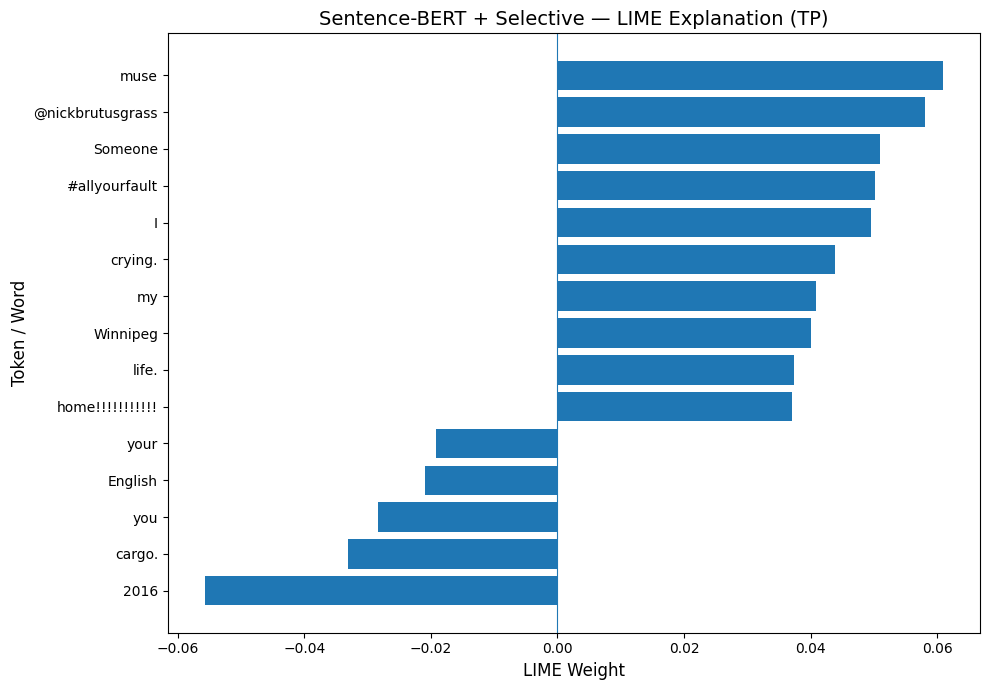

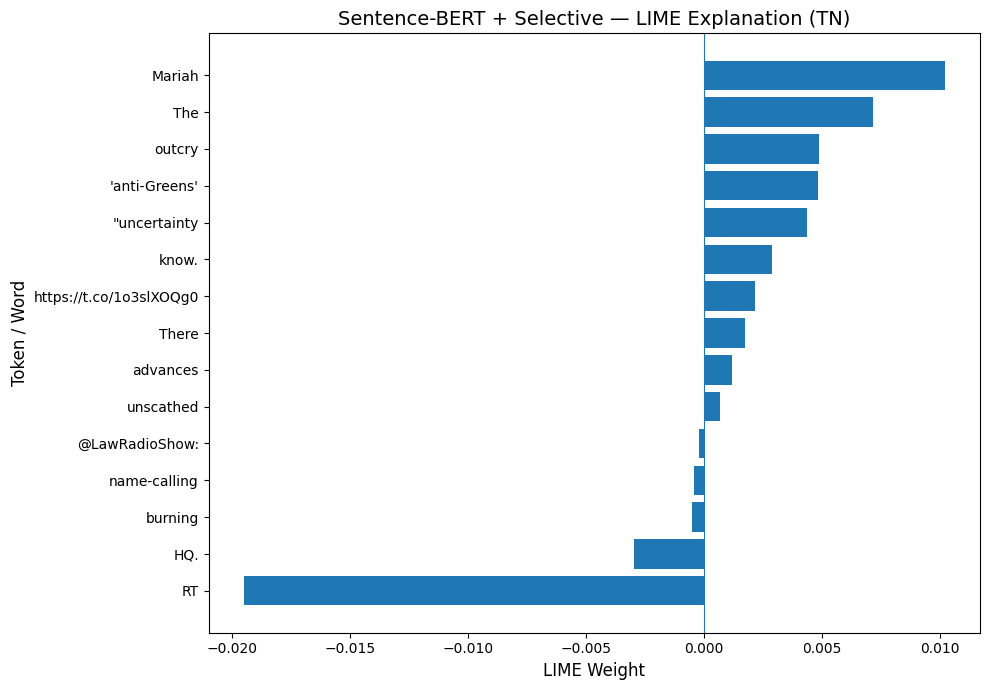

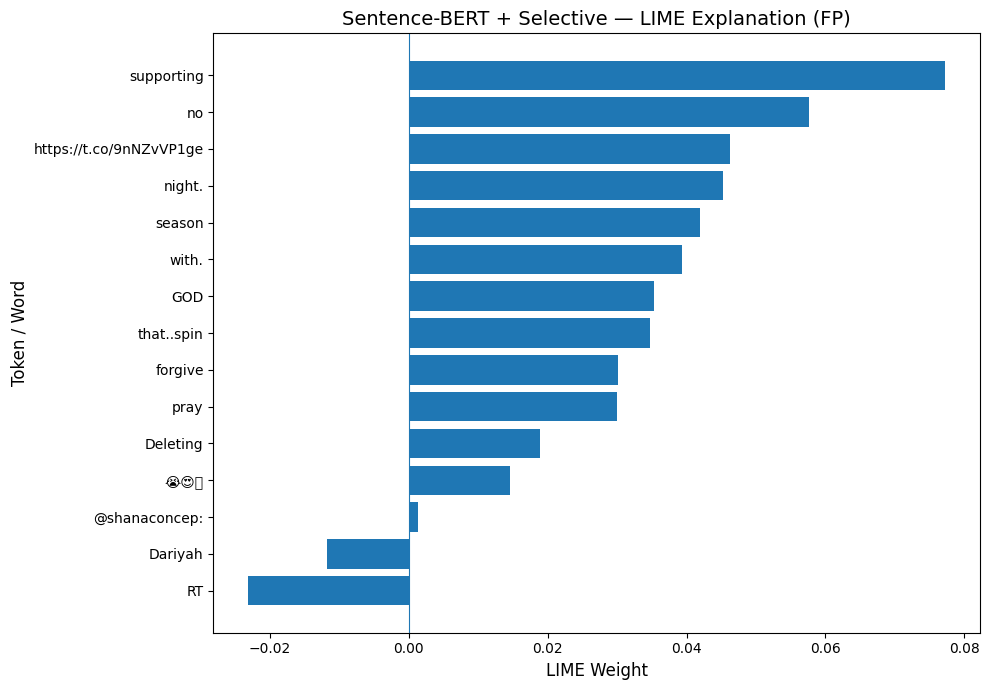

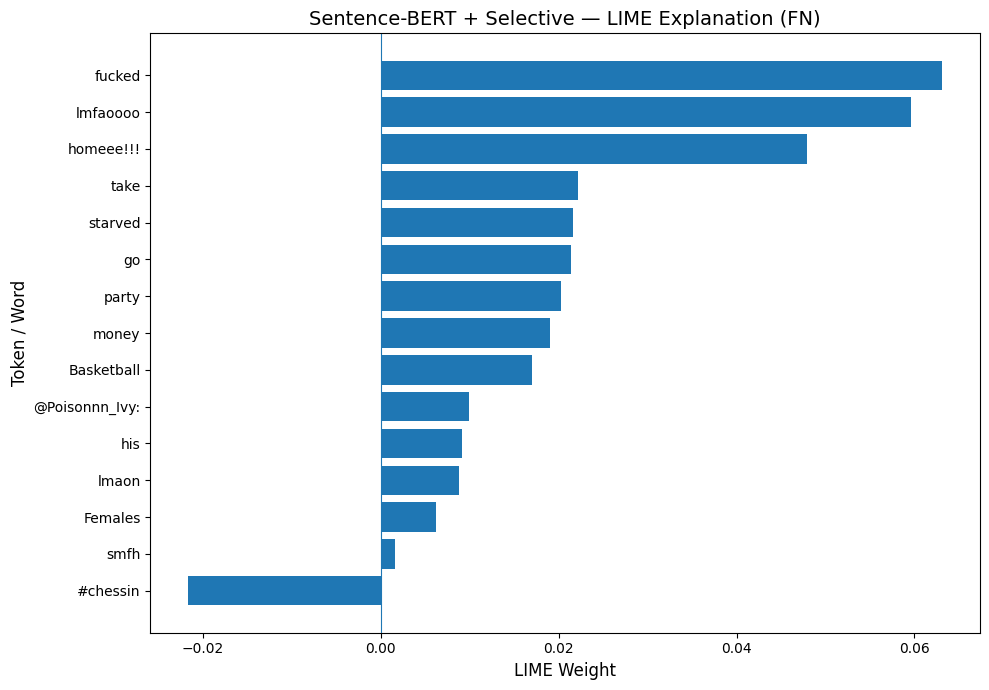


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained Sentence-BERT + Selective model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/sentencebert_raw/explainability/lime


In [29]:
# ============================================================
# EXPLAINABILITY — LIME
# SENTENCE-BERT + SELECTIVE
# TOKEN / WORD-LEVEL LOCAL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML


print("=" * 70)
print("LIME EXPLAINABILITY")
print("SENTENCE-BERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_SAMPLES = 1000
LIME_NUM_FEATURES = 15
LIME_BATCH_SIZE = 8

np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model.eval()

print(
    "✓ Sentence-BERT + Selective model loaded"
)

print(
    "✓ Evaluation mode enabled"
)


# ============================================================
# TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []


with torch.no_grad():

    for batch in test_sentencebert_raw_loader:

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = output[
            "logits"
        ]

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        labels_np.extend(
            batch[
                "labels"
            ]
            .cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions
            .cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()
        )


labels_np = np.array(
    labels_np
)

preds_np = np.array(
    preds_np
)

probs_np = np.array(
    probs_np
)


print()
print("=" * 70)
print("TEST PREDICTIONS READY")
print("=" * 70)

print(
    "Test samples:",
    len(labels_np)
)


# ============================================================
# SELECT TP / TN / FP / FN
# ============================================================

selected_cases = {}


tp_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 1)
)[0]


tn_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 0)
)[0]


fp_candidates = np.where(
    (labels_np == 0)
    &
    (preds_np == 1)
)[0]


fn_candidates = np.where(
    (labels_np == 1)
    &
    (preds_np == 0)
)[0]


if len(tp_candidates) > 0:

    selected_cases[
        "TP"
    ] = int(
        tp_candidates[0]
    )


if len(tn_candidates) > 0:

    selected_cases[
        "TN"
    ] = int(
        tn_candidates[0]
    )


if len(fp_candidates) > 0:

    selected_cases[
        "FP"
    ] = int(
        fp_candidates[0]
    )


if len(fn_candidates) > 0:

    selected_cases[
        "FN"
    ] = int(
        fn_candidates[0]
    )


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)


for case_name, test_index in selected_cases.items():

    print(
        f"{case_name} : "
        f"test index {test_index} | "
        f"true={labels_np[test_index]} | "
        f"pred={preds_np[test_index]} | "
        f"probability={probs_np[test_index]:.4f}"
    )


# ============================================================
# GET TEST TEXT
# ============================================================


def get_test_text(test_index):

    return str(
        test_sentencebert_raw_df.iloc[
            test_index
        ]["model_text"]
    )

# ============================================================
# CREATE LIME PREDICTOR
# TEXT VARIES
# METADATA REMAINS FIXED
# ============================================================

def make_lime_predictor(test_index):

    sample = test_sentencebert_raw_dataset[
        test_index
    ]

    fixed_metadata = (
        sample[
            "metadata"
        ]
        .unsqueeze(0)
        .to(device)
        .float()
    )


    def predictor(texts):

        all_probabilities = []


        # ----------------------------------------------------
        # PROCESS LIME PERTURBATIONS IN SMALL BATCHES
        # TO AVOID GPU OUT-OF-MEMORY
        # ----------------------------------------------------

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            batch_texts = texts[
                start:
                start + LIME_BATCH_SIZE
            ]


            encoded = sentencebert_raw_tokenizer(
                batch_texts,
                padding="max_length",
                truncation=True,
                max_length=MAX_LENGTH,
                return_attention_mask=True,
                return_tensors="pt"
            )


            lime_input_ids = (
                encoded[
                    "input_ids"
                ]
                .to(device)
            )


            lime_attention_mask = (
                encoded[
                    "attention_mask"
                ]
                .to(device)
            )


            batch_metadata = (
                fixed_metadata.expand(
                    len(batch_texts),
                    -1
                )
            )


            with torch.no_grad():

                output = model(
                    input_ids=lime_input_ids,
                    attention_mask=lime_attention_mask,
                    metadata=batch_metadata
                )


                probabilities = torch.softmax(
                    output[
                        "logits"
                    ],
                    dim=1
                )


            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )


            del (
                lime_input_ids,
                lime_attention_mask,
                batch_metadata,
                output,
                probabilities
            )


            if torch.cuda.is_available():

                torch.cuda.empty_cache()


        return np.vstack(
            all_probabilities
        )


    return predictor


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)


# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}


print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)


for case_name, test_index in selected_cases.items():

    print()

    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )


    text = get_test_text(
        test_index
    )


    predictor = make_lime_predictor(
        test_index
    )


    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )


    all_explanations[
        case_name
    ] = explanation


    print(
        f"✓ {case_name} explanation complete"
    )


# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []


for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )


    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(
                    weight
                )
        })


lime_results_df = pd.DataFrame(
    all_lime_rows
)


lime_csv_path = os.path.join(
    LIME_DIR,
    "sentencebert_selective_lime_results.csv"
)


lime_results_df.to_csv(
    lime_csv_path,
    index=False
)


# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)


for case_name, explanation in all_explanations.items():

    print()

    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )


    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )


    html_path = os.path.join(
        LIME_DIR,
        f"sentencebert_selective_lime_{case_name}.html"
    )


    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )


# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = (
        explanation.as_list(
            label=1
        )
    )


    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )


    plot_df = plot_df.sort_values(
        "weight"
    )


    plt.figure(
        figsize=(10, 7)
    )


    plt.barh(
        plot_df[
            "word"
        ],
        plot_df[
            "weight"
        ]
    )


    plt.axvline(
        0,
        linewidth=0.8
    )


    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )


    plt.ylabel(
        "Token / Word",
        fontsize=12
    )


    plt.title(
        (
            "Sentence-BERT + Selective — "
            f"LIME Explanation ({case_name})"
        ),
        fontsize=14
    )


    plt.tight_layout()


    plot_path = os.path.join(
        LIME_DIR,
        f"sentencebert_selective_lime_{case_name}.png"
    )


    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []


for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(
                test_index
            ),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )
    })


case_info_df = pd.DataFrame(
    case_info_rows
)


case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "sentencebert_selective_lime_case_information.csv"
    ),
    index=False
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "Sentence-BERT",

    "model_name":
        MODEL_NAME,

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training",

    "transformer_weights":
        "Frozen"
}


with open(
    os.path.join(
        LIME_DIR,
        "sentencebert_selective_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained Sentence-BERT + Selective model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    f"✓ {LIME_NUM_SAMPLES} LIME perturbations per case"
)

print(
    f"✓ Top {LIME_NUM_FEATURES} features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()

print(
    "LIME output directory:",
    LIME_DIR
)

In [30]:
# Check user overlap between splits

train_ids = set(train_df["user_id"])
val_ids = set(val_df["user_id"])
test_ids = set(test_df["user_id"])

print("Train users:", len(train_ids))
print("Validation users:", len(val_ids))
print("Test users:", len(test_ids))

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train users: 6135
Validation users: 767
Test users: 767
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [31]:
checkpoint = torch.load(
    "/kaggle/working/sentencebert_raw/checkpoints/best_sentencebert_raw.pt",
    map_location=device,
    weights_only=False
)

print("Checkpoint keys:", checkpoint.keys())

print("Best epoch:", checkpoint.get("epoch"))
print("Best validation F1:", checkpoint.get("val_f1"))

Checkpoint keys: dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'best_val_f1', 'model_name', 'cleaning_method'])
Best epoch: 10
Best validation F1: None


In [32]:
test_results_df

,user_id,username,true_label,predicted_label,positive_probability
0,166046144,seanamulcahy,0,0,0.134091
1,24816724,sachaleebear,1,1,0.792717
2,97945564,xoxoevelynn,0,0,0.057148
3,1520670242,asemmd,1,1,0.989508
4,2542853210,Sejal_srt_sr3,0,0,0.019325
...,...,...,...,...,...
762,184872561,PitbullGirlUK,1,1,0.994930
763,803919960124715008,Mafuyu_yukituru,0,0,0.008212
764,633868228,_alexandria3,0,0,0.351184
765,705578797,Htgr8,1,1,0.928892


In [33]:
print("Best validation F1:", checkpoint["best_val_f1"])
print("Model name:", checkpoint["model_name"])
print("Cleaning method:", checkpoint["cleaning_method"])

Best validation F1: 0.8522072936660269
Model name: sentence-transformers/all-mpnet-base-v2
Cleaning method: RAW


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Extract actual and predicted labels
y_true = test_results_df["true_label"]
y_pred = test_results_df["predicted_label"]
y_prob = test_results_df["positive_probability"]

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_prob)

print("INDEPENDENT TEST VERIFICATION")
print("=" * 50)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

INDEPENDENT TEST VERIFICATION
Accuracy:  0.9296
Precision: 0.8745
Recall:    0.9163
F1 Score:  0.8949
ROC-AUC:   0.9744

Confusion Matrix:
[[483  33]
 [ 21 230]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       516
           1       0.87      0.92      0.89       251

    accuracy                           0.93       767
   macro avg       0.92      0.93      0.92       767
weighted avg       0.93      0.93      0.93       767



In [35]:
print("Total rows:", len(test_results_df))
print("Unique user IDs:", test_results_df["user_id"].nunique())
print("Duplicate user IDs:",
      test_results_df["user_id"].duplicated().sum())

Total rows: 767
Unique user IDs: 767
Duplicate user IDs: 0
